In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Section 1 - EDA 


In [46]:
# Load the Data
df = pd.read_csv('Data/diamonds_unsupervised.csv')

In [47]:
# First Step - Simple Statistics about the dataset. 

# Basic Statistics
print("--- Basic Statistics ---")
print(display(df.describe()))



--- Basic Statistics ---


,carat,depth_pct,table_pct,price_usd,length_mm,width_mm,height_mm,color_grade,clarity_grade
count,5023.000000,4993.000000,4993.000000,5023.000000,5023.000000,5023.000000,5023.000000,5023.000000,5023.000000
mean,0.870346,62.216343,58.121690,4148.845112,5.875509,5.882532,3.649606,4.328887,3.763289
std,0.500671,2.275648,2.820193,3966.817759,1.135406,1.396637,0.840823,1.714410,1.624898
min,0.210000,50.800000,44.000000,337.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,0.460000,61.000000,56.000000,1108.000000,4.900000,4.890000,3.020000,3.000000,3.000000
50%,0.800000,62.100000,58.000000,2883.000000,5.920000,5.900000,3.680000,4.000000,4.000000
75%,1.060000,63.500000,59.000000,5440.500000,6.570000,6.570000,4.090000,6.000000,5.000000
max,5.010000,79.000000,95.000000,18818.000000,10.740000,58.900000,31.800000,7.000000,8.000000


None


### Missing values - Depth and table percentage


In [48]:
# Missing Values
print("\n--- Missing Values Count ---")
print(display(df.isnull().sum()))


--- Missing Values Count ---


diamond_id        0
carat             0
depth_pct        30
table_pct        30
price_usd         0
length_mm         0
width_mm          0
height_mm         0
color_grade       0
clarity_grade     0
dtype: int64

None


#### Depth - The proportion in percentage between the height of the diamond to the diameter. 
#### Table - The proportion in percentage between the upper flat surface to the diameter.

A questions arises whether to delete these missing values or complete them? 

In [49]:
# Firstly we will check the percentage of missing rows
total_rows = len(df)
missing_rows = df['table_pct'].isnull().sum()
print(f"Percentage of missing data: {(missing_rows / total_rows) * 100:.4f}%")

# We will calculate the missing depth_pct exactly with length, width, and height exist
mask = df['depth_pct'].isnull() & (df['length_mm'] > 0) & (df['width_mm'] > 0)

# Formula: (Height / Average of Length and Width) * 100
df.loc[mask, 'depth_pct'] = (df['height_mm'] / ((df['length_mm'] + df['width_mm']) / 2)) * 100

print(f"Remaining missing in depth_pct: {df['depth_pct'].isnull().sum()}")

# Separate the data into missing table_pct and normal data
missing_table = df[df['table_pct'].isnull()]
normal_table = df[~df['table_pct'].isnull()]

# Compare the average Carat and Price between missing table and non-missing table
print("--- Bias Check for Missing table_pct ---")
print(f"Missing rows average Carat: {missing_table['carat'].mean():.2f}")
print(f"Normal rows average Carat: {normal_table['carat'].mean():.2f}")

print(f"Missing rows average Price: ${missing_table['price_usd'].mean():.2f}")
print(f"Normal rows average Price: ${normal_table['price_usd'].mean():.2f}")

Percentage of missing data: 0.5973%
Remaining missing in depth_pct: 0
--- Bias Check for Missing table_pct ---
Missing rows average Carat: 0.82
Normal rows average Carat: 0.87
Missing rows average Price: $3903.47
Normal rows average Price: $4150.32


#### We decided to compute Depth, and remove table


### Duplicate Rows
#### Because diamonds are naturally occurring and cut individually, the chances of two distinct diamonds having the exact same continuous measurements (length, width, height, depth, table) alongside the exact same carat weight and price are virtually zero.

In [50]:
# Remove the 'diamond_id' column
df = df.drop(columns=['diamond_id'])

# Check how many duplicates exist now that the ID is gone
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {num_duplicates}")

# View the duplicated rows (sorted so identical rows appear next to each other)
if num_duplicates > 0:
    print("\n--- Showing Duplicate Rows ---")
    duplicates = df[df.duplicated(keep=False)].sort_values(by=['carat', 'price_usd'])
    print(duplicates)

# Drop the duplicates (keeps the first occurrence, removes the rest)
df = df.drop_duplicates()

print(f"\nDataset size after dropping duplicates: {df.shape}")

Number of duplicate rows found: 6

--- Showing Duplicate Rows ---
      carat  depth_pct  table_pct  price_usd  length_mm  width_mm  height_mm  \
813    0.50       79.0       73.0       2579       5.21      5.18       4.09   
4237   0.50       79.0       73.0       2579       5.21      5.18       4.09   
570    0.60       63.2       60.0       1250       5.32      5.28       3.35   
2500   0.60       63.2       60.0       1250       5.32      5.28       3.35   
4057   0.71       64.1       60.0       2130       0.00      0.00       0.00   
4901   0.71       64.1       60.0       2130       0.00      0.00       0.00   
1596   1.50       65.0       57.0       6838       7.10      7.06       4.60   
4762   1.50       65.0       57.0       6838       7.10      7.06       4.60   
1728   2.01       65.9       57.0      10887       7.85      7.78       5.15   
3729   2.01       65.9       57.0      10887       7.85      7.78       5.15   
2498   3.01       65.8       56.0      18242       8.9

### Impossible values - 
Diamonds have physical attributes therefore carat, length, width, price, height cannot be less or equal to 0. 

In [51]:
# Identify rows where height_mm is 0, but depth_pct and other dimensions are valid
recoverable_mask = (df['height_mm'] <= 0) & (df['depth_pct'] > 0) & (df['length_mm'] > 0) & (df['width_mm'] > 0)

print(f"Number of 0-height rows that can be recovered: {recoverable_mask.sum()}")

# Mathematically recover the height_mm
# Formula reverse-engineered: height_mm = (depth_pct / 100) * Average(length, width)
df.loc[recoverable_mask, 'height_mm'] = (df['depth_pct'] / 100) * ((df['length_mm'] + df['width_mm']) / 2)

# Now define the mask for any REMAINING impossible values
impossible_mask = (
    (df['length_mm'] <= 0) | 
    (df['width_mm'] <= 0) | 
    (df['height_mm'] <= 0) |
    (df['carat'] <= 0) |
    (df['price_usd'] <= 0)
)

print(f"Number of remaining impossible rows to drop: {impossible_mask.sum()}")

# Drop only the ones that truly couldn't be saved
df = df[~impossible_mask]
print(f"Dataset size after recovery and dropping: {df.shape}")

Number of 0-height rows that can be recovered: 12
Number of remaining impossible rows to drop: 7
Dataset size after recovery and dropping: (5010, 9)


### Graph 1: The Market (Histograms)
#### Story: What is the most common diamond?


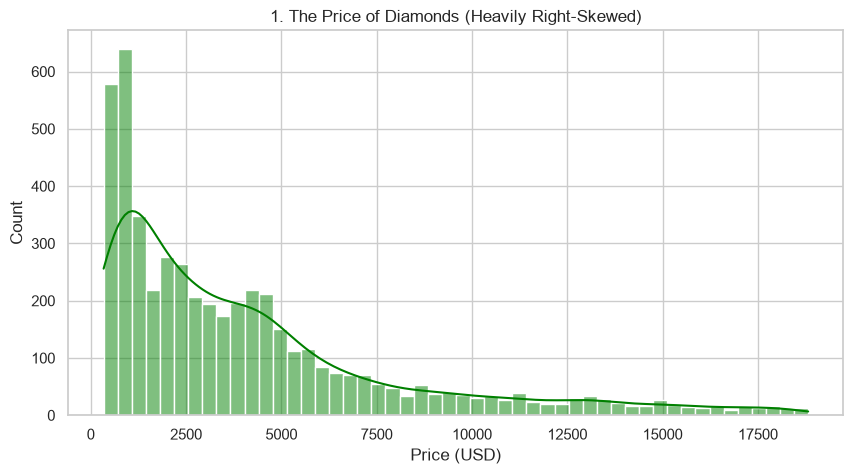

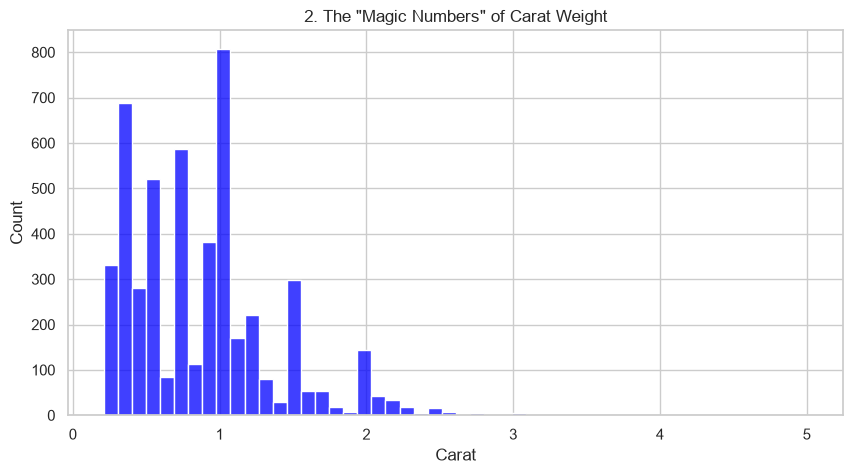

In [ ]:
# Set a clean visual style for the story
sns.set_theme(style="whitegrid")

# Graph 1: Distribution of Price
# Insight: The market is heavily skewed right. Most diamonds are relatively cheap, but there is a long tail of luxury stones.
plt.figure(figsize=(10, 5))
sns.histplot(df['price_usd'], bins=50, color='green', kde=True)
plt.title('1. The Price of Diamonds (Heavily Right-Skewed)')
plt.xlabel('Price (USD)')
plt.show()

# Graph 2: Distribution of Carat Weight
# Insight: Notice the massive spikes at "magic numbers" like 0.5, 1.0, 1.5, and 2.0 carats. Cutters intentionally save weight to hit these profitable milestones.
plt.figure(figsize=(10, 5))
sns.histplot(df['carat'], bins=50, color='blue')
plt.title('Carat Vs. Amount')
plt.xlabel('Carat')
plt.show()


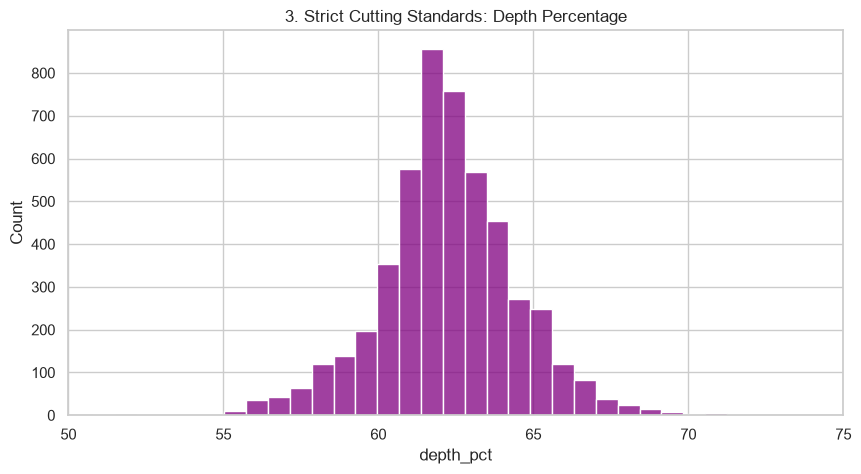

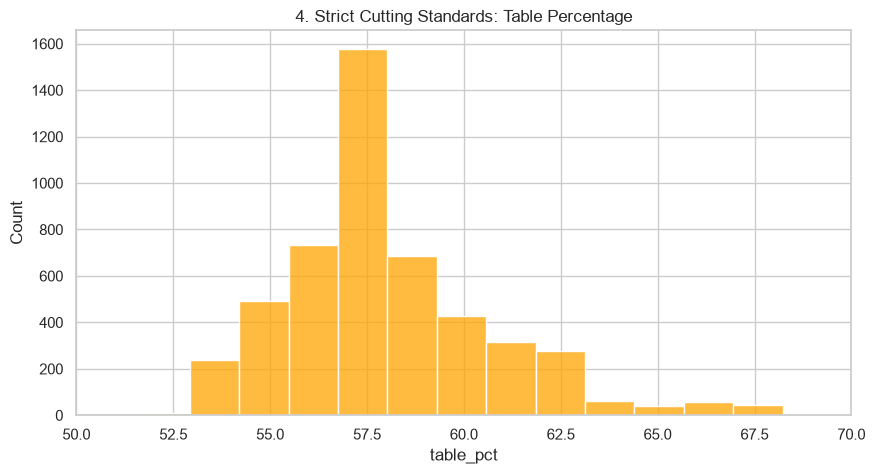

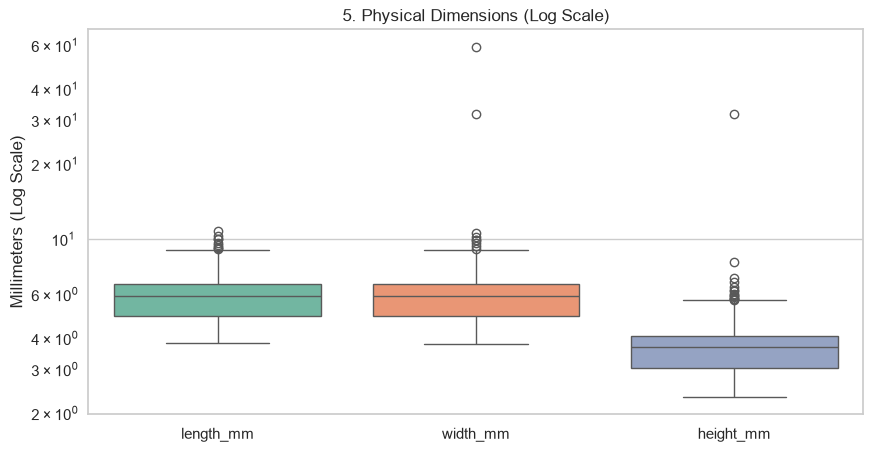

In [56]:
# Set a clean visual style for the story
sns.set_theme(style="whitegrid")

# PART 2: The Cut Proportions
# Story: Are diamonds cut randomly, or to a strict standard?

# Graph 3: Distribution of Depth Percentage
# Insight: Depth is normally distributed and highly concentrated between 60-63%. This is the mathematical "sweet spot" for maximizing sparkle.
plt.figure(figsize=(10, 5))
sns.histplot(df['depth_pct'], bins=40, color='purple')
plt.title('3. Strict Cutting Standards: Depth Percentage')
plt.xlim(50, 75) # Zooming in on the main data
plt.show()

# Graph 4: Distribution of Table Percentage
# Insight: Similar to depth, the flat top of the diamond (table) is strictly kept between 55-60% to ensure light bounces correctly.
plt.figure(figsize=(10, 5))
sns.histplot(df['table_pct'], bins=40, color='orange')
plt.title('4. Strict Cutting Standards: Table Percentage')
plt.xlim(50, 70)
plt.show()

# Graph 5: Outliers in Physical Dimensions
# Insight: Boxplots show us that while most dimensions are tight, there are a few extreme outliers (potentially bad data or massive stones).
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[['length_mm', 'width_mm', 'height_mm']], palette='Set2')
plt.title('5. Physical Dimensions (Log Scale)')
plt.ylabel('Millimeters (Log Scale)')

# This line changes the y-axis to a logarithmic scale
plt.yscale('log') 

plt.show()



C:\Users\User\AppData\Local\Temp\ipykernel_24704\2398873100.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='color_grade', y='price_usd', data=df, order=color_order, palette='coolwarm')


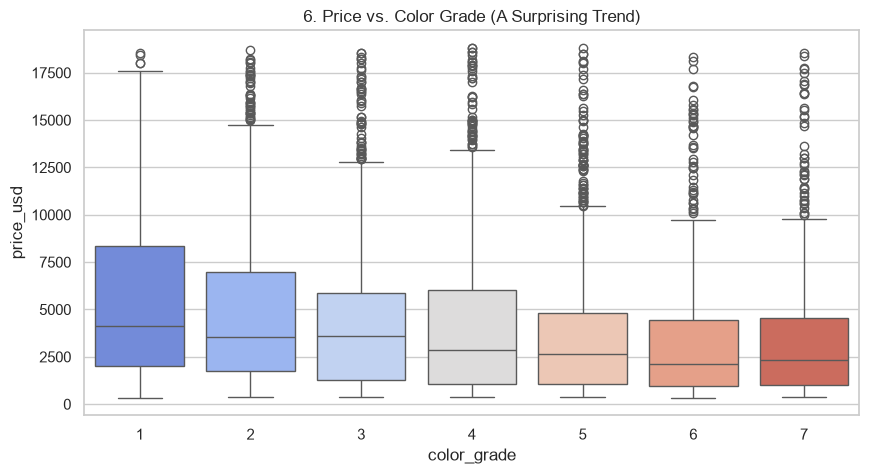

C:\Users\User\AppData\Local\Temp\ipykernel_24704\2398873100.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='clarity_grade', y='price_usd', data=df, order=clarity_order, palette='viridis')


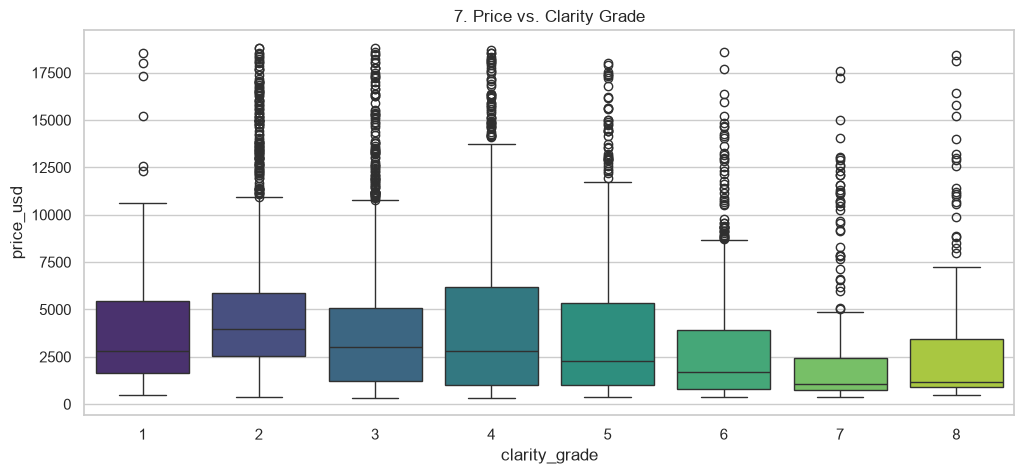

C:\Users\User\AppData\Local\Temp\ipykernel_24704\2398873100.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='color_grade', y='carat', data=df, order=color_order, palette='coolwarm')


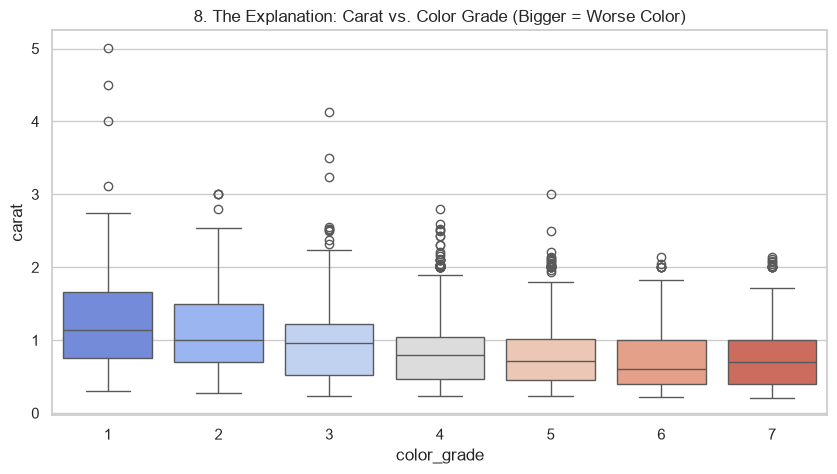

In [57]:
# Set a clean visual style for the story
sns.set_theme(style="whitegrid")

# ==========================================
# PART 3: The Value Drivers - Color and Clarity (Boxplots)
# Story: Does better quality always mean a higher price?
# ==========================================

# Graph 6: Price vs. Color Grade
# Insight: Counter-intuitively, the "worst" colors (like J) might actually have a higher median price than the "best" colors (like D). Why? (Graph 8 will explain).
plt.figure(figsize=(10, 5))
# Assuming grades D (best) to J (worst)
color_order = sorted(df['color_grade'].dropna().unique()) 
sns.boxplot(x='color_grade', y='price_usd', data=df, order=color_order, palette='coolwarm')
plt.title('6. Price vs. Color Grade (A Surprising Trend)')
plt.show()

# Graph 7: Price vs. Clarity Grade
# Insight: Similar to color, you might see that "flawless" diamonds aren't the most expensive on average. 
plt.figure(figsize=(12, 5))
clarity_order = sorted(df['clarity_grade'].dropna().unique())
sns.boxplot(x='clarity_grade', y='price_usd', data=df, order=clarity_order, palette='viridis')
plt.title('7. Price vs. Clarity Grade')
plt.show()

# Graph 8: Carat vs. Color Grade (The Explanation)
# Insight: This boxplot explains Graph 6. The "worst" colors are significantly heavier (higher carat) on average. People sacrifice color to afford a larger diamond, and size drives the price more than color!
plt.figure(figsize=(10, 5))
sns.boxplot(x='color_grade', y='carat', data=df, order=color_order, palette='coolwarm')
plt.title('8. The Explanation: Carat vs. Color Grade (Bigger = Worse Color)')
plt.show()

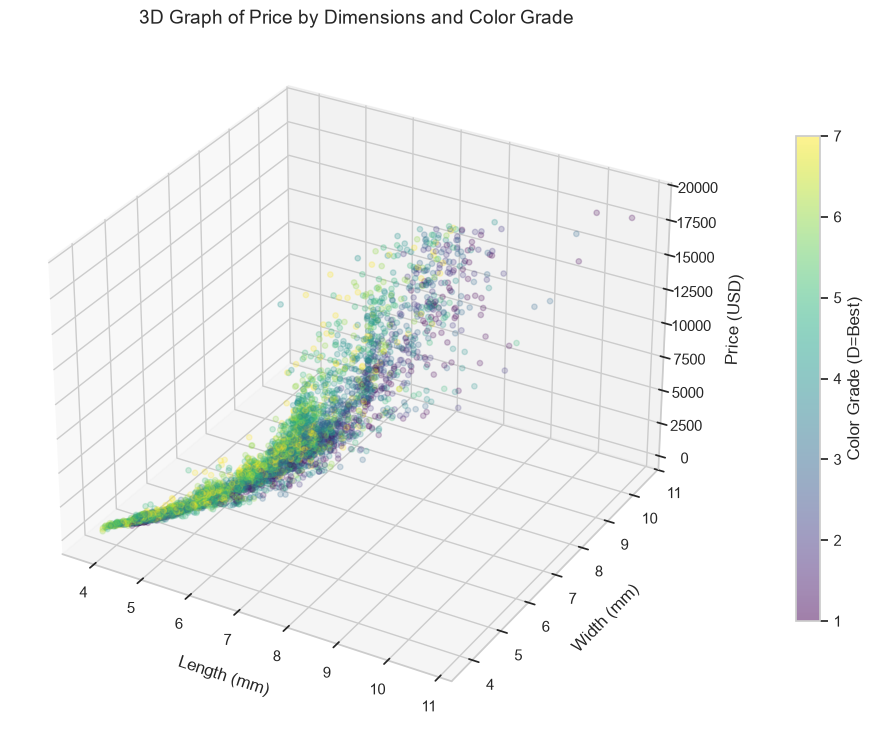

In [58]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filter outliers so the 3D plot is actually readable 
# Keeping dimensions under 15mm based on our previous findings
plot_df = df[(df['length_mm'] < 15) & (df['width_mm'] < 15) & (df['height_mm'] < 15)].copy()

# Drop rows with missing colors to avoid plotting errors
plot_df = plot_df.dropna(subset=['color_grade', 'price_usd', 'length_mm', 'width_mm'])

# 2. Map text color grades to numbers for the color map
color_order = sorted(plot_df['color_grade'].unique())
color_mapping = {grade: i for i, grade in enumerate(color_order)}
plot_df['color_num'] = plot_df['color_grade'].map(color_mapping)

# 3. Set up the 3D figure
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 4. Plot the data
# X = Length, Y = Width, Z = Price, c = Color Grade
scatter = ax.scatter(
    plot_df['length_mm'], 
    plot_df['width_mm'], 
    plot_df['price_usd'],
    c=plot_df['color_num'], 
    cmap='viridis',      # The color palette
    alpha=0.5,           # Slight transparency so overlapping points are visible
    s=15                 # Size of the dots
)

# 5. Label the axes
ax.set_xlabel('Length (mm)', labelpad=10)
ax.set_ylabel('Width (mm)', labelpad=10)
ax.set_zlabel('Price (USD)', labelpad=10)
ax.set_title('3D Graph of Price by Dimensions and Color Grade', fontsize=14)

# 6. Create a custom legend for the color grades
cbar = plt.colorbar(scatter, ax=ax, pad=0.1, shrink=0.7)
cbar.set_ticks(range(len(color_order)))
cbar.set_ticklabels(color_order)
cbar.set_label('Color Grade (D=Best)')

plt.show()

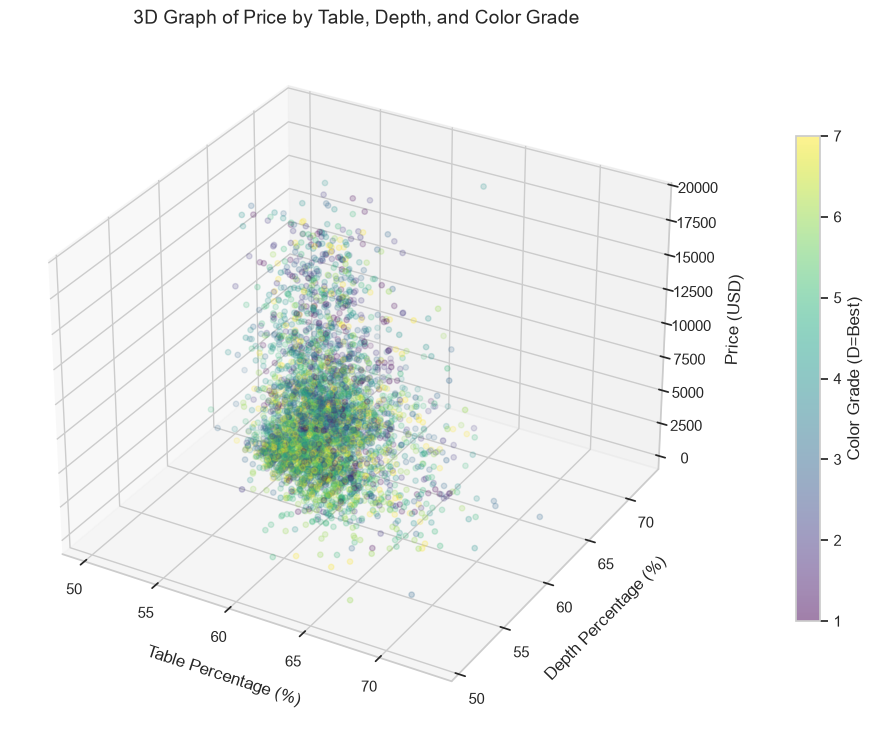

In [59]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filter outliers to keep the 3D plot readable 
# Typical diamond table and depth percentages fall between 50% and 75%
plot_df = df[(df['table_pct'] > 50) & (df['table_pct'] < 75) & 
             (df['depth_pct'] > 50) & (df['depth_pct'] < 75)].copy()

# Drop rows with missing values in these specific columns
plot_df = plot_df.dropna(subset=['color_grade', 'price_usd', 'table_pct', 'depth_pct'])

# 2. Map text color grades to numbers for the color map
color_order = sorted(plot_df['color_grade'].unique())
color_mapping = {grade: i for i, grade in enumerate(color_order)}
plot_df['color_num'] = plot_df['color_grade'].map(color_mapping)

# 3. Set up the 3D figure
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 4. Plot the data
# X = Table %, Y = Depth %, Z = Price, c = Color Grade
scatter = ax.scatter(
    plot_df['table_pct'], 
    plot_df['depth_pct'], 
    plot_df['price_usd'],
    c=plot_df['color_num'], 
    cmap='viridis',      # The color palette
    alpha=0.5,           # Transparency
    s=15                 # Size of the dots
)

# 5. Label the axes
ax.set_xlabel('Table Percentage (%)', labelpad=10)
ax.set_ylabel('Depth Percentage (%)', labelpad=10)
ax.set_zlabel('Price (USD)', labelpad=10)
ax.set_title('3D Graph of Price by Table, Depth, and Color Grade', fontsize=14)

# 6. Create a custom legend for the color grades
cbar = plt.colorbar(scatter, ax=ax, pad=0.1, shrink=0.7)
cbar.set_ticks(range(len(color_order)))
cbar.set_ticklabels(color_order)
cbar.set_label('Color Grade (D=Best)')

plt.show()

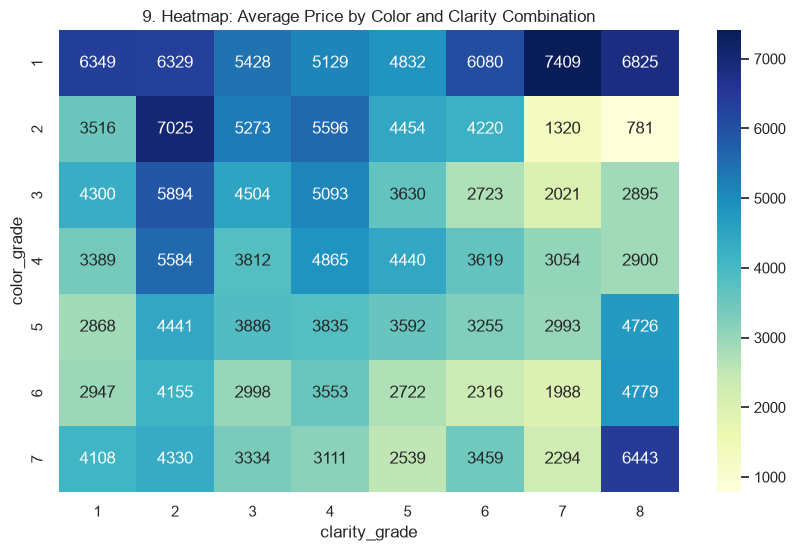

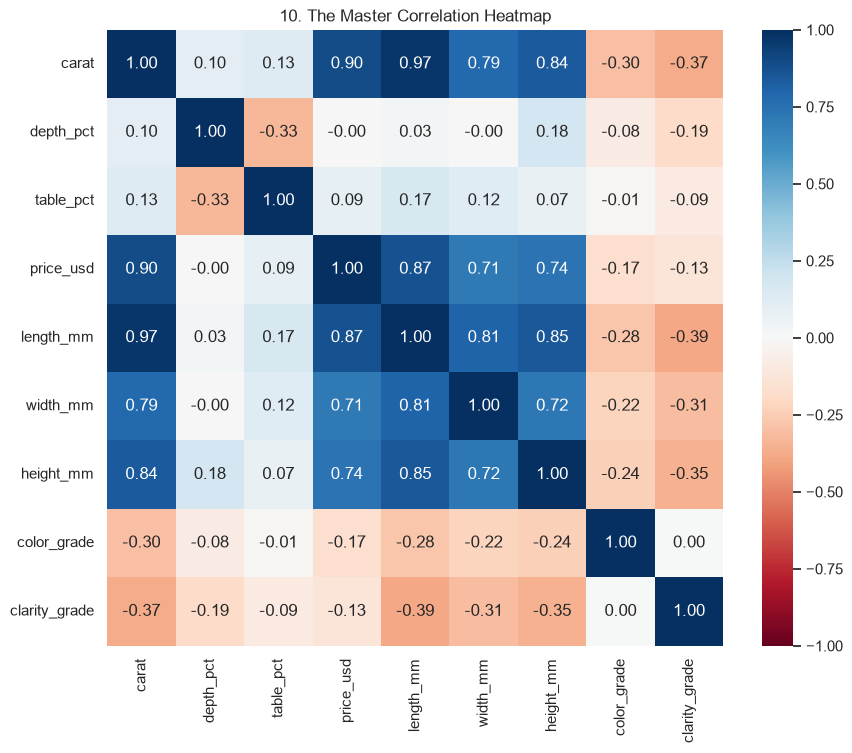

In [60]:
# Set a clean visual style for the story
sns.set_theme(style="whitegrid")
# ==========================================
# PART 4: The Big Picture (Heatmaps)
# Story: How do all these variables interact at once?
# ==========================================

# Graph 9: Average Price by Color and Clarity Matrix
# Insight: This heatmap turns categorical data into a color map. It shows exactly which combination of color and clarity yields the highest average price.
plt.figure(figsize=(10, 6))
# Create a pivot table summarizing the average price for each color/clarity combo
price_pivot = df.pivot_table(index='color_grade', columns='clarity_grade', values='price_usd', aggfunc='mean')
sns.heatmap(price_pivot, annot=True, fmt=".0f", cmap='YlGnBu')
plt.title('9. Heatmap: Average Price by Color and Clarity Combination')
plt.show()

# Graph 10: The Ultimate Correlation Matrix
# Insight: The grand finale. Carat and Dimensions (length, width, height) are near-perfectly correlated (almost 1.0). Price is heavily driven by Carat. Depth and Table have almost zero correlation with Price.
plt.figure(figsize=(10, 8))
# Calculate correlation only on numeric columns
corr_matrix = df.select_dtypes(include='number').corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu', fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title('10. The Master Correlation Heatmap')
plt.show()

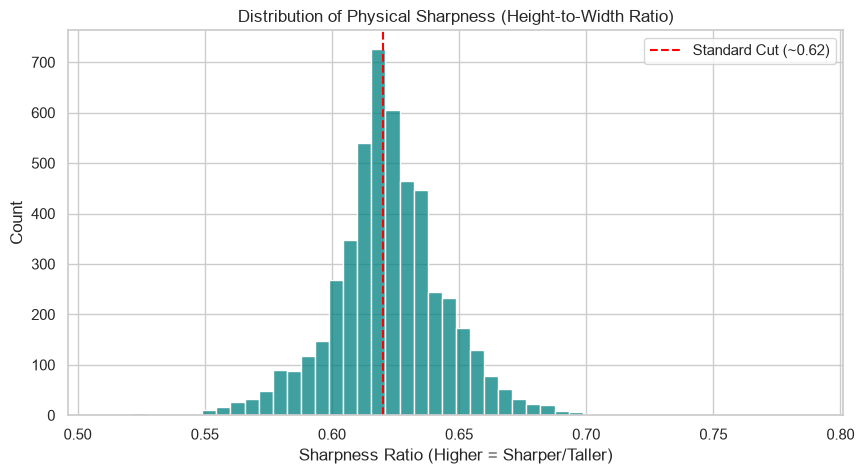

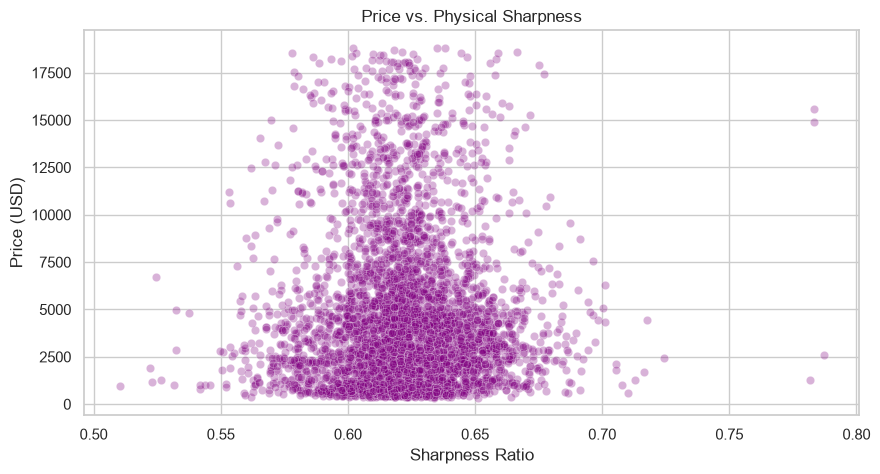

Correlation between physical sharpness and price: 0.003


In [62]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculate Physical Sharpness
# Sharpness Ratio = Height / Average of Length and Width
# (A standard diamond is ~0.60. A "sharp" diamond might be 0.75+)
df['sharpness_ratio'] = df['height_mm'] / ((df['length_mm'] + df['width_mm']) / 2)

# Filter out the extreme outliers so the graphs are readable
plot_df = df[(df['sharpness_ratio'] > 0.4) & (df['sharpness_ratio'] < 1.0)].copy()

# ==========================================
# Question 1: Are physically sharp diamonds common?
# ==========================================
plt.figure(figsize=(10, 5))
sns.histplot(plot_df['sharpness_ratio'], bins=50, color='teal')
plt.title('Distribution of Physical Sharpness (Height-to-Width Ratio)')
plt.xlabel('Sharpness Ratio (Higher = Sharper/Taller)')
plt.axvline(x=0.62, color='red', linestyle='--', label='Standard Cut (~0.62)')
plt.legend()
plt.show()

# What to expect: 
# You will see a massive spike right around 0.61 - 0.63. 
# Sharp diamonds are NOT common. Cutters avoid making them because a diamond that is too tall/sharp leaks light out of the bottom and loses its sparkle.

# ==========================================
# Question 2: Are sharp diamonds more expensive?
# ==========================================
plt.figure(figsize=(10, 5))
sns.scatterplot(x='sharpness_ratio', y='price_usd', data=plot_df, alpha=0.3, color='purple')
plt.title('Price vs. Physical Sharpness')
plt.xlabel('Sharpness Ratio')
plt.ylabel('Price (USD)')
plt.show()

# Calculate the actual correlation number
correlation = plot_df['sharpness_ratio'].corr(plot_df['price_usd'])
print(f"Correlation between physical sharpness and price: {correlation:.3f}")

# What to expect:
# The correlation will likely be near 0 (or even slightly negative). 
# Because "sharp" diamonds don't sparkle as well, they are considered poorly cut. Buyers pay a premium for standard proportions (the

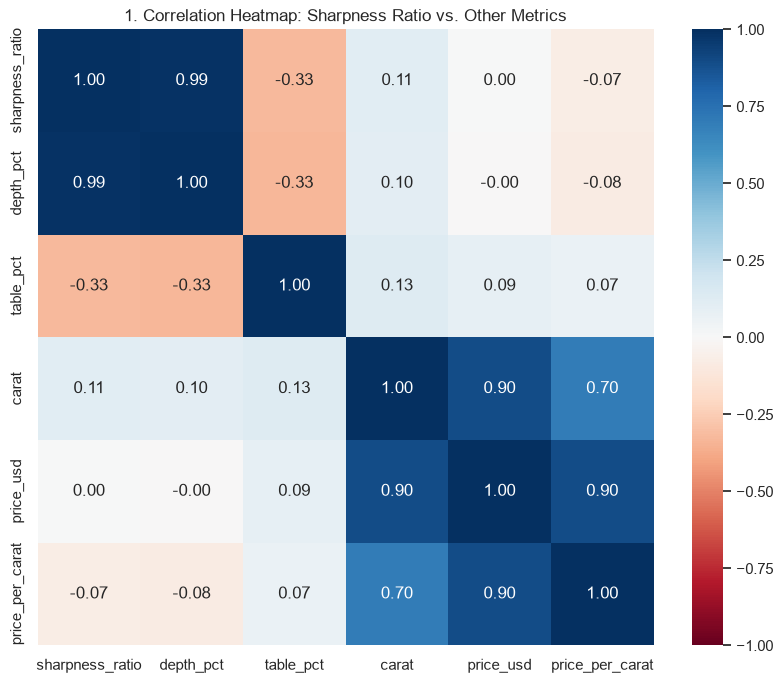

C:\Users\User\AppData\Local\Temp\ipykernel_24704\366607111.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='clarity_grade', y='sharpness_ratio', data=plot_df, order=clarity_order, palette='Set2')


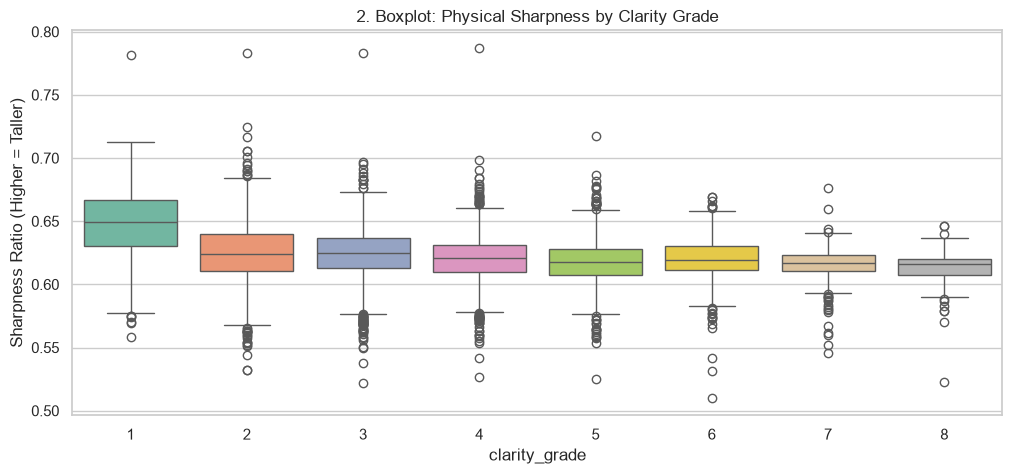

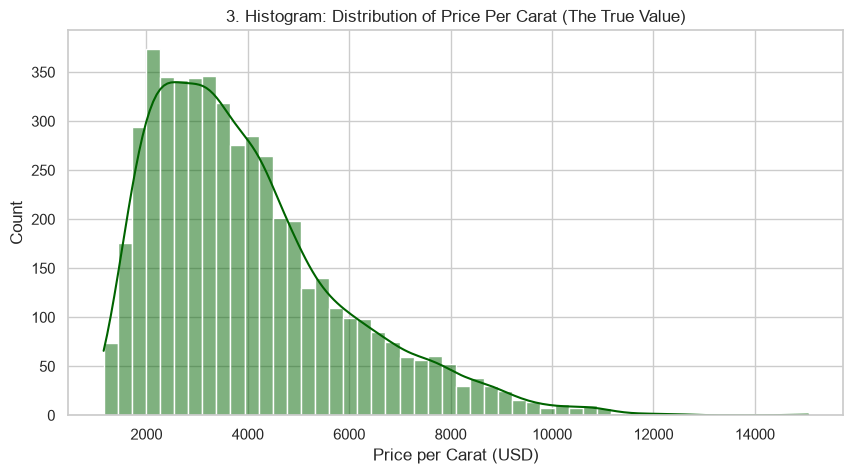

C:\Users\User\AppData\Local\Temp\ipykernel_24704\366607111.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='color_grade', y='price_per_carat', data=plot_df, order=color_order, palette='coolwarm')


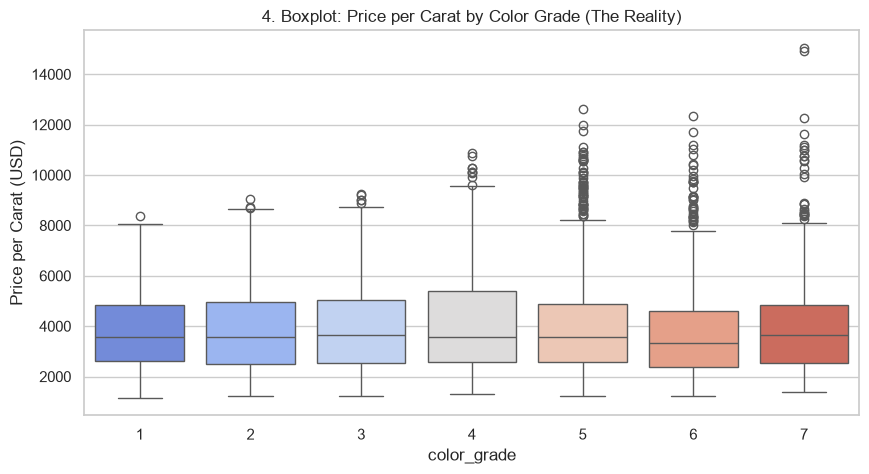

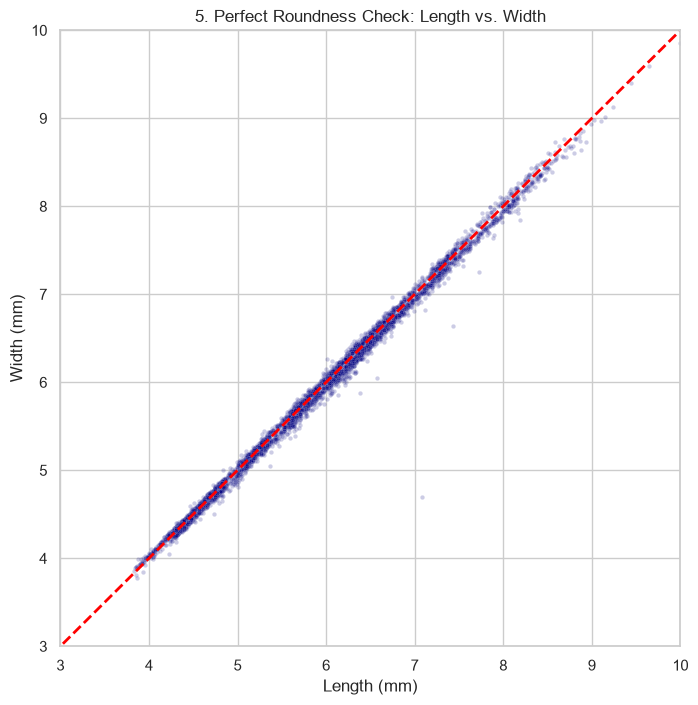

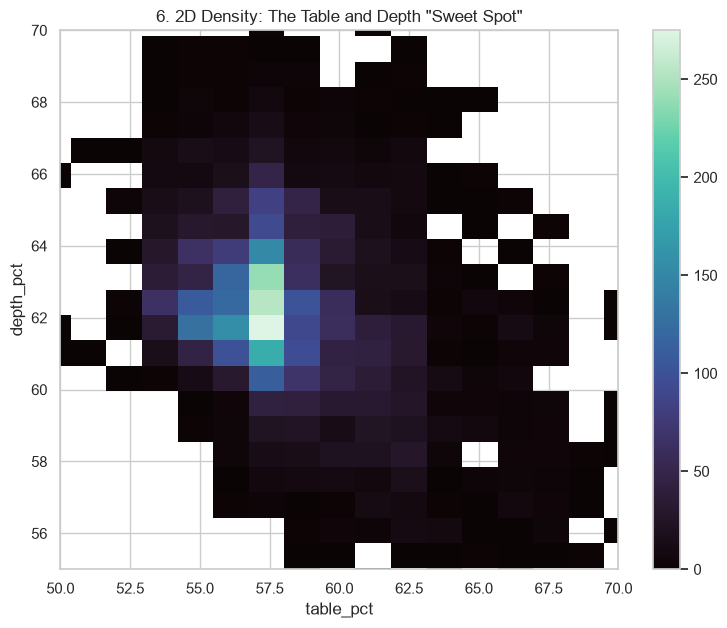

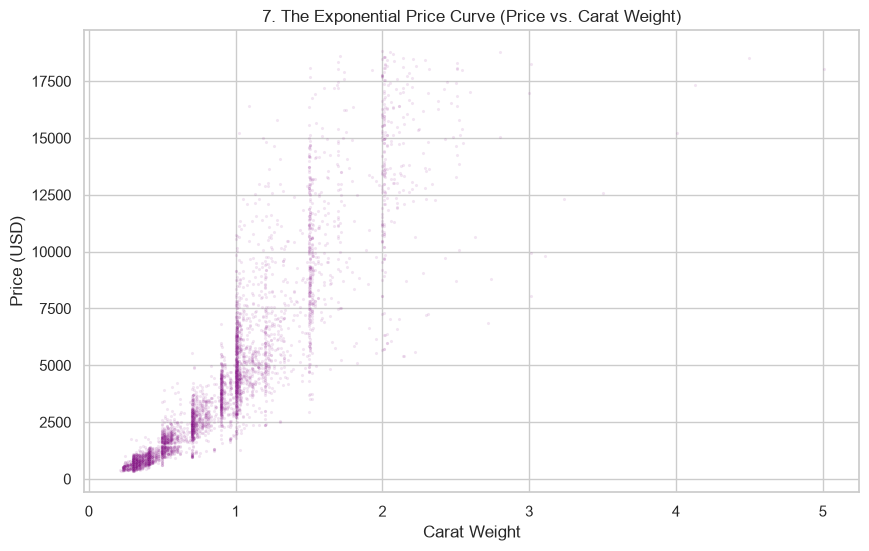

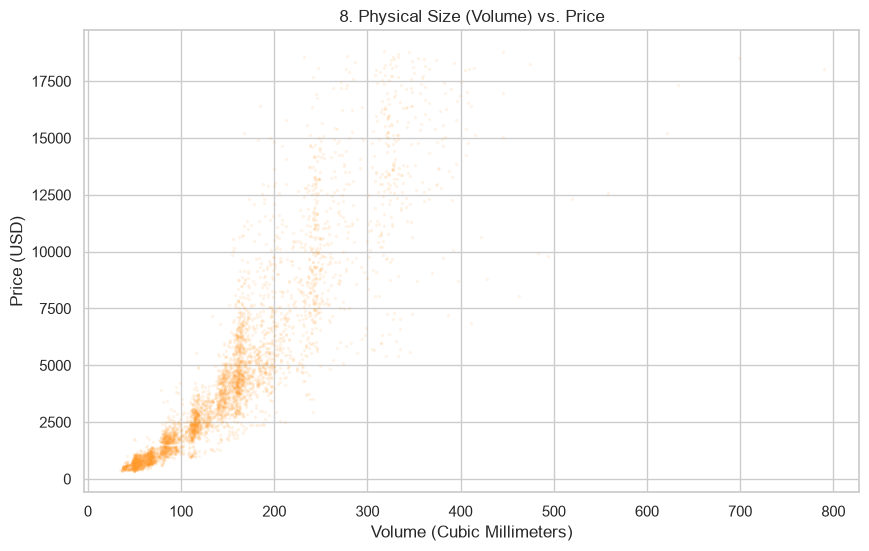

C:\Users\User\AppData\Local\Temp\ipykernel_24704\366607111.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='carat_bin', y='table_pct', data=plot_df, palette='magma')


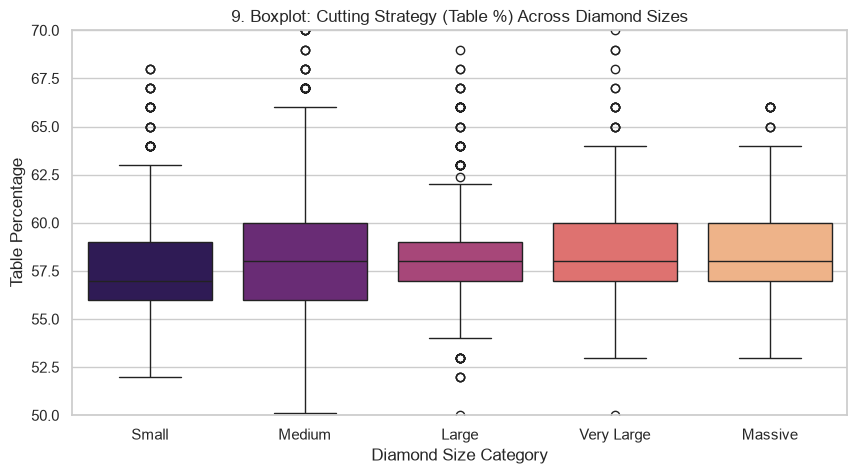

In [63]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 0. Feature Engineering & Setup
# ==========================================
# Add the sharpness ratio directly to the main dataframe
df['sharpness_ratio'] = df['height_mm'] / ((df['length_mm'] + df['width_mm']) / 2)

# Create a 'price_per_carat' column. This levels the playing field so we can judge quality, not just weight.
df['price_per_carat'] = df['price_usd'] / df['carat']

# Filter extreme outliers so the graphs remain visually readable (keeping realistic ranges)
plot_df = df[(df['sharpness_ratio'] > 0.4) & (df['sharpness_ratio'] < 0.8) & 
             (df['length_mm'] < 15) & (df['width_mm'] < 15) & (df['height_mm'] < 15)].copy()

sns.set_theme(style="whitegrid")

# ==========================================
# GRAPH 1: The Sharpness Correlation Heatmap
# ==========================================
# Insight: Does physical sharpness correlate with depth percentage? Yes, heavily! Does it correlate with price? No.
plt.figure(figsize=(10, 8))
corr_cols = ['sharpness_ratio', 'depth_pct', 'table_pct', 'carat', 'price_usd', 'price_per_carat']
corr_matrix = plot_df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu', fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title('1. Correlation Heatmap: Sharpness Ratio vs. Other Metrics')
plt.show()


# ==========================================
# GRAPH 2: Sharpness vs. Clarity (Boxplot)
# ==========================================
# Insight: Does the physical shape (sharpness) change depending on how clear the diamond is? 
# Usually, flawless diamonds are cut to stricter standards (tighter boxes).
plt.figure(figsize=(12, 5))
clarity_order = sorted(plot_df['clarity_grade'].dropna().unique())
sns.boxplot(x='clarity_grade', y='sharpness_ratio', data=plot_df, order=clarity_order, palette='Set2')
plt.title('2. Boxplot: Physical Sharpness by Clarity Grade')
plt.ylabel('Sharpness Ratio (Higher = Taller)')
plt.show()


# ==========================================
# GRAPH 3: True Value - Price per Carat Distribution (Histogram)
# ==========================================
# Insight: While raw price is skewed, price per carat shows us the true "premium" people pay for quality.
plt.figure(figsize=(10, 5))
sns.histplot(plot_df['price_per_carat'], bins=50, color='darkgreen', kde=True)
plt.title('3. Histogram: Distribution of Price Per Carat (The True Value)')
plt.xlabel('Price per Carat (USD)')
plt.show()


# ==========================================
# GRAPH 4: Price per Carat vs. Color Grade (Boxplot)
# ==========================================
# Insight: In our earlier graphs, worse colors seemed more expensive because they were heavier. 
# By using Price per Carat, we finally see the truth: Better colors (D) are worth more pound-for-pound.
plt.figure(figsize=(10, 5))
color_order = sorted(plot_df['color_grade'].dropna().unique())
sns.boxplot(x='color_grade', y='price_per_carat', data=plot_df, order=color_order, palette='coolwarm')
plt.title('4. Boxplot: Price per Carat by Color Grade (The Reality)')
plt.ylabel('Price per Carat (USD)')
plt.show()


# ==========================================
# GRAPH 5: Length vs Width - The "Perfect Roundness" Check (Scatter/Line)
# ==========================================
# Insight: A perfectly round diamond will sit exactly on a 1:1 diagonal line. 
# Any dots drifting away from the line are oval or poorly cut diamonds.
plt.figure(figsize=(8, 8))
sns.scatterplot(x='length_mm', y='width_mm', data=plot_df, alpha=0.2, color='navy', s=10)
# Adding a red reference line for perfect roundness (1:1 ratio)
plt.plot([0, 10], [0, 10], color='red', linestyle='--', linewidth=2)
plt.title('5. Perfect Roundness Check: Length vs. Width')
plt.xlabel('Length (mm)')
plt.ylabel('Width (mm)')
plt.xlim(3, 10)
plt.ylim(3, 10)
plt.show()


# ==========================================
# GRAPH 6: Table vs Depth "Sweet Spot" (2D Histogram / Density Heatmap)
# ==========================================
# Insight: Cutters aim for a strict bullseye to maximize sparkle (Table ~57%, Depth ~61%). 
# This 2D histogram acts as a heatmap showing exactly where the industry clusters its cuts.
plt.figure(figsize=(9, 7))
sns.histplot(x='table_pct', y='depth_pct', data=plot_df, bins=40, cmap='mako', cbar=True)
plt.title('6. 2D Density: The Table and Depth "Sweet Spot"')
plt.xlim(50, 70)
plt.ylim(55, 70)
plt.show()


# ==========================================
# GRAPH 7: The Carat Weight vs Price Curve (Scatter)
# ==========================================
# Insight: Price does not increase linearly with weight; it curves upward exponentially.
# A 2-carat diamond is much more than twice the price of a 1-carat diamond.
plt.figure(figsize=(10, 6))
sns.scatterplot(x='carat', y='price_usd', data=plot_df, alpha=0.1, color='purple', s=5)
plt.title('7. The Exponential Price Curve (Price vs. Carat Weight)')
plt.xlabel('Carat Weight')
plt.ylabel('Price (USD)')
plt.show()


# ==========================================
# GRAPH 8: Volume vs. Price (Scatter)
# ==========================================
# Insight: Carat is weight, but volume (L * W * H) is physical size. 
# Are people paying for density or size? They track almost perfectly together.
plot_df['volume_mm3'] = plot_df['length_mm'] * plot_df['width_mm'] * plot_df['height_mm']
plt.figure(figsize=(10, 6))
sns.scatterplot(x='volume_mm3', y='price_usd', data=plot_df, alpha=0.1, color='darkorange', s=5)
plt.title('8. Physical Size (Volume) vs. Price')
plt.xlabel('Volume (Cubic Millimeters)')
plt.ylabel('Price (USD)')
plt.show()


# ==========================================
# GRAPH 9: Table Percentage Anomalies (Boxplot)
# ==========================================
# Insight: Are larger diamonds cut with different table percentages than smaller ones?
# We can bin the carats into sizes to see if the cutting strategy changes for massive stones.
plot_df['carat_bin'] = pd.cut(plot_df['carat'], bins=[0, 0.5, 1.0, 1.5, 2.0, 5.0], labels=['Small', 'Medium', 'Large', 'Very Large', 'Massive'])
plt.figure(figsize=(10, 5))
sns.boxplot(x='carat_bin', y='table_pct', data=plot_df, palette='magma')
plt.title('9. Boxplot: Cutting Strategy (Table %) Across Diamond Sizes')
plt.xlabel('Diamond Size Category')
plt.ylabel('Table Percentage')
plt.ylim(50, 70)
plt.show()

Generating Group A: 1D Distributions...


C:\Users\User\AppData\Local\Temp\ipykernel_24704\175718837.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='color_grade', ax=axes[2, 1], order=color_order, palette='viridis')
C:\Users\User\AppData\Local\Temp\ipykernel_24704\175718837.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='clarity_grade', ax=axes[2, 2], order=clarity_order, palette='viridis')


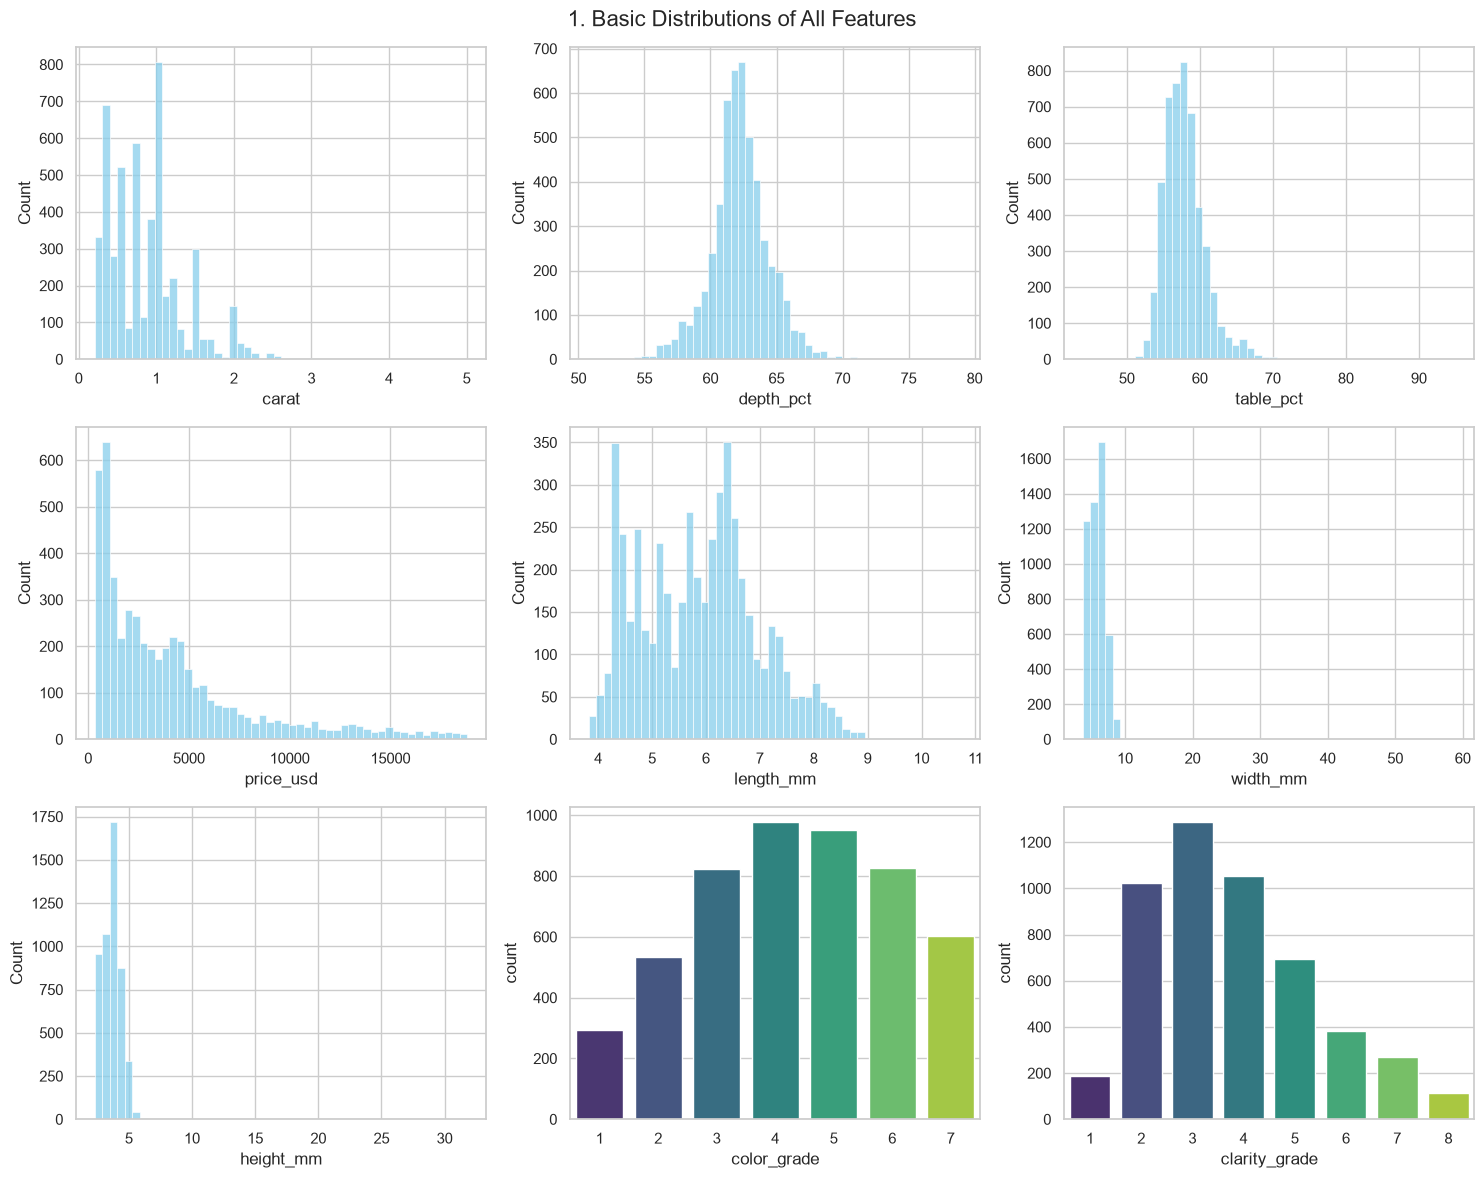

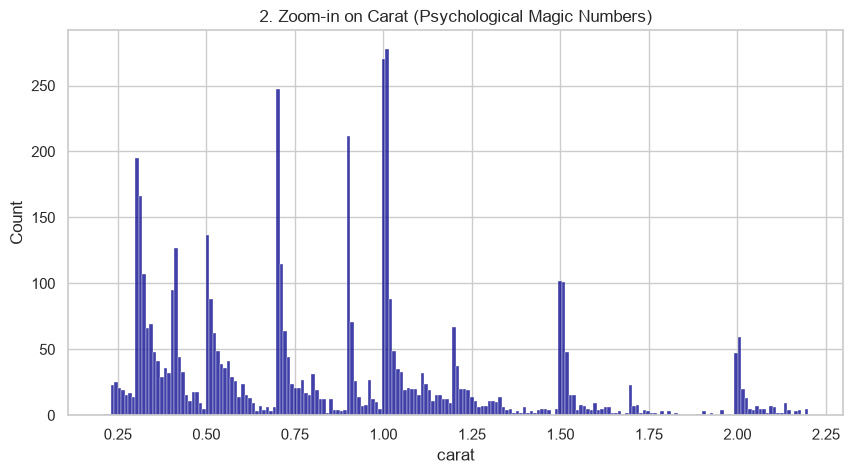

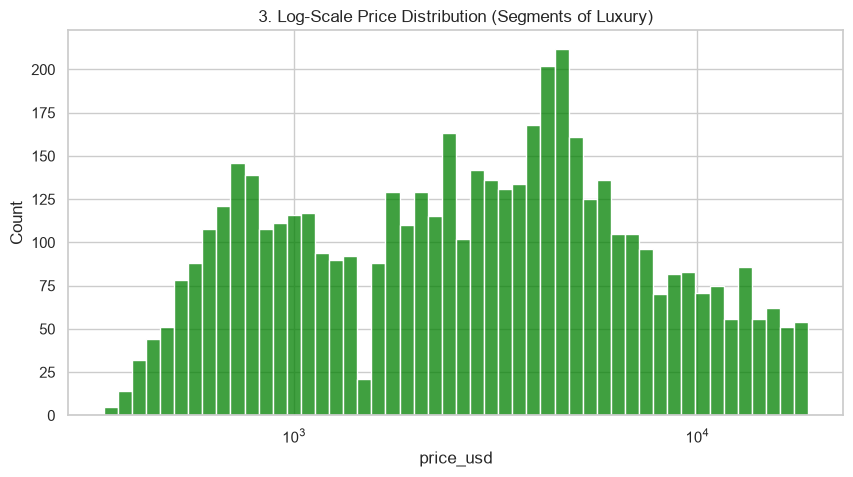

Generating Group B: Carat vs Price...


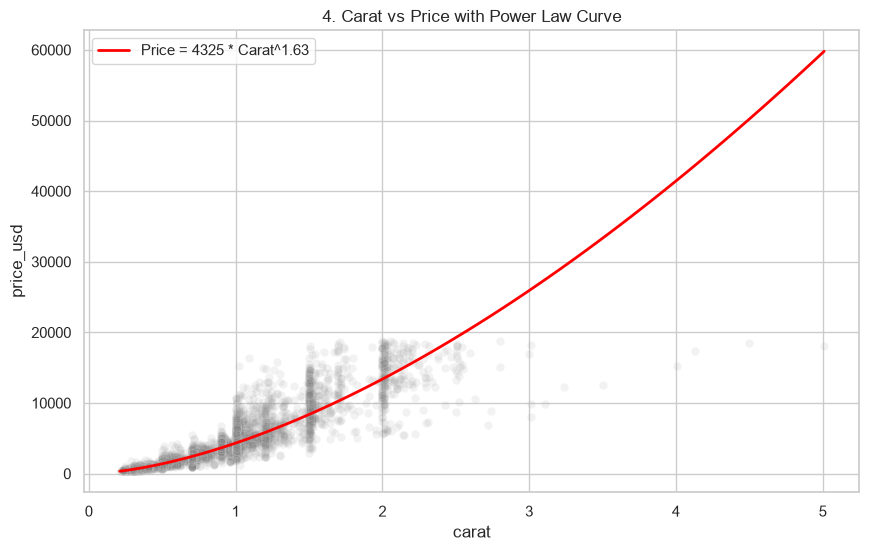

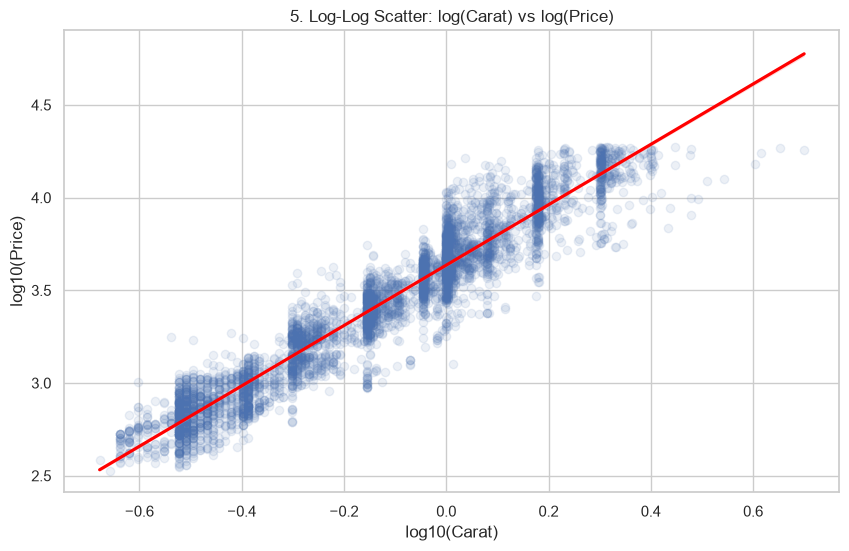

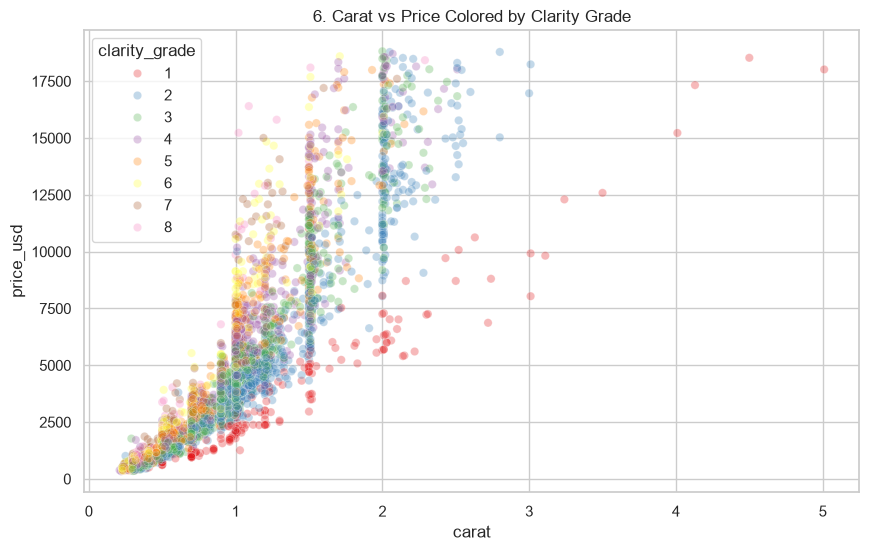

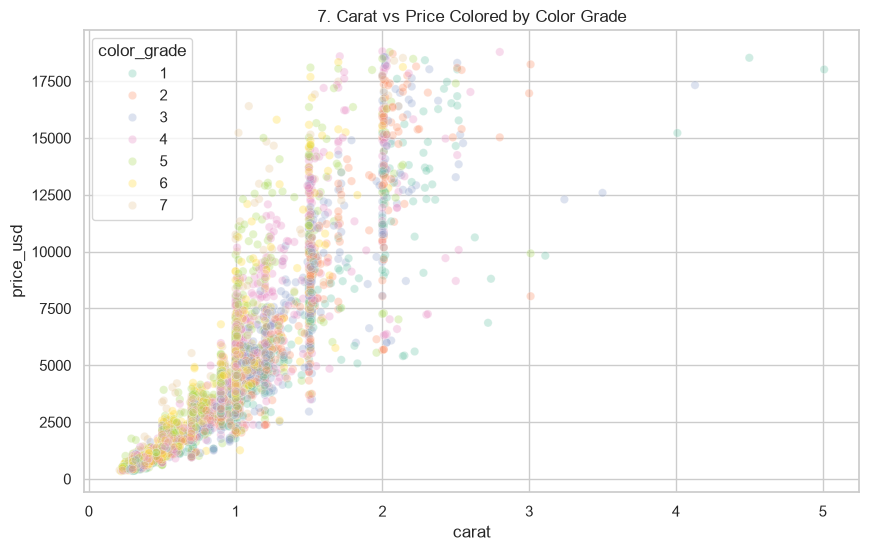

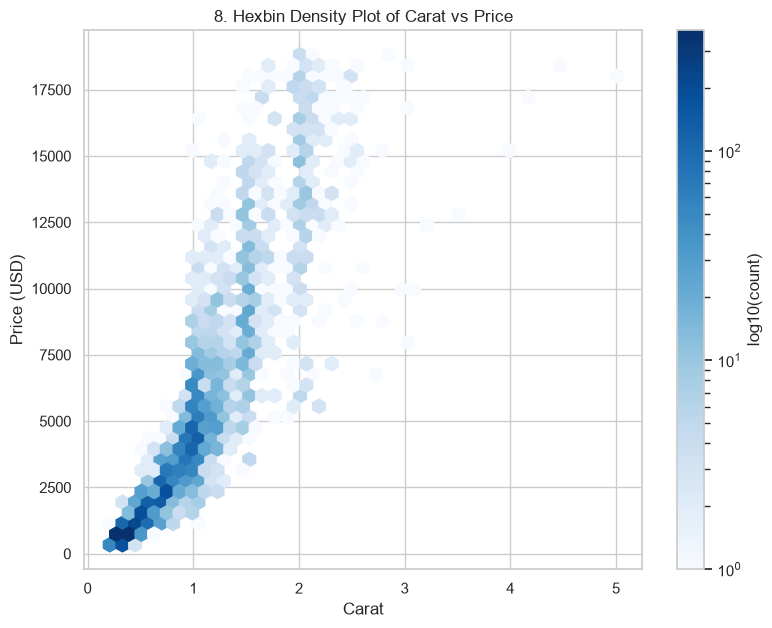

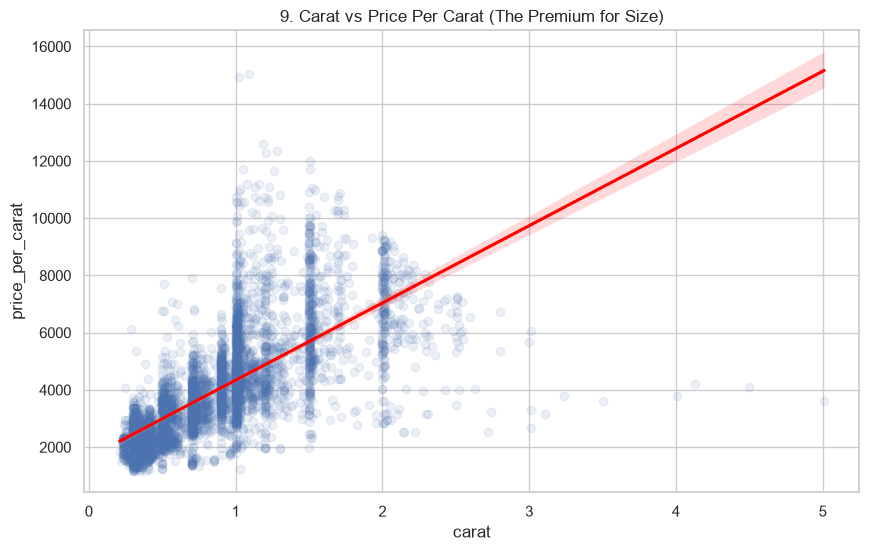

Generating Group C: Color & Clarity Paradoxes...


C:\Users\User\AppData\Local\Temp\ipykernel_24704\175718837.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(x='color_grade', y='price_usd', data=df, order=color_order, palette='coolwarm')


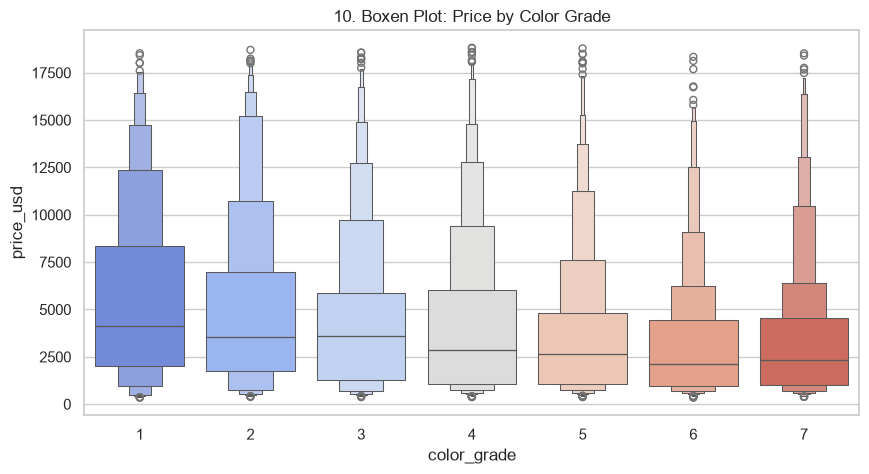

C:\Users\User\AppData\Local\Temp\ipykernel_24704\175718837.py:130: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(x='clarity_grade', y='price_usd', data=df, order=clarity_order, palette='viridis')


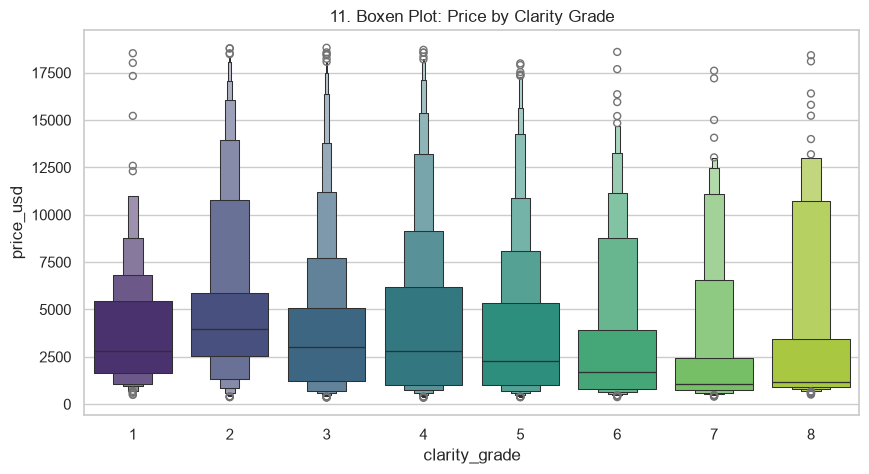

C:\Users\User\AppData\Local\Temp\ipykernel_24704\175718837.py:136: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='clarity_grade', y='carat', data=df, order=clarity_order, palette='muted')


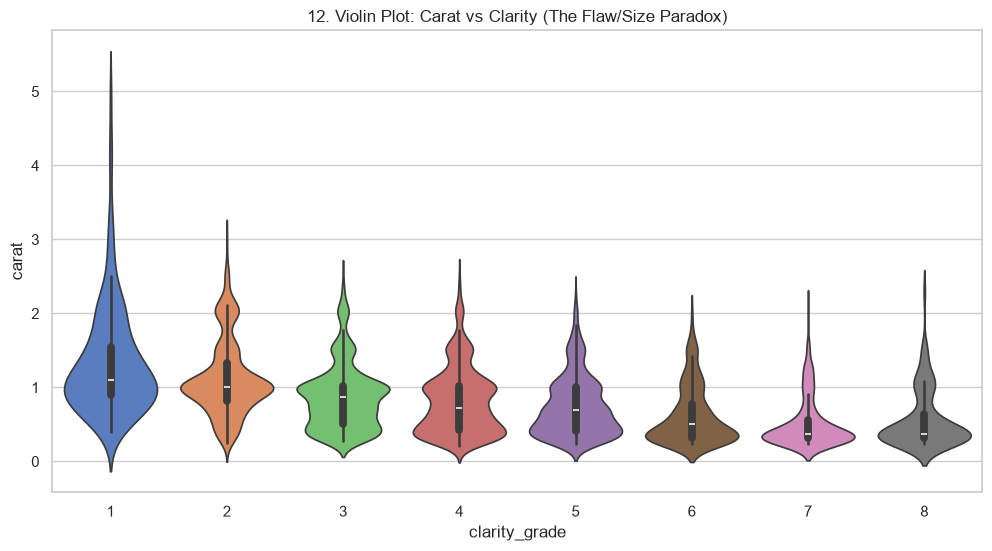

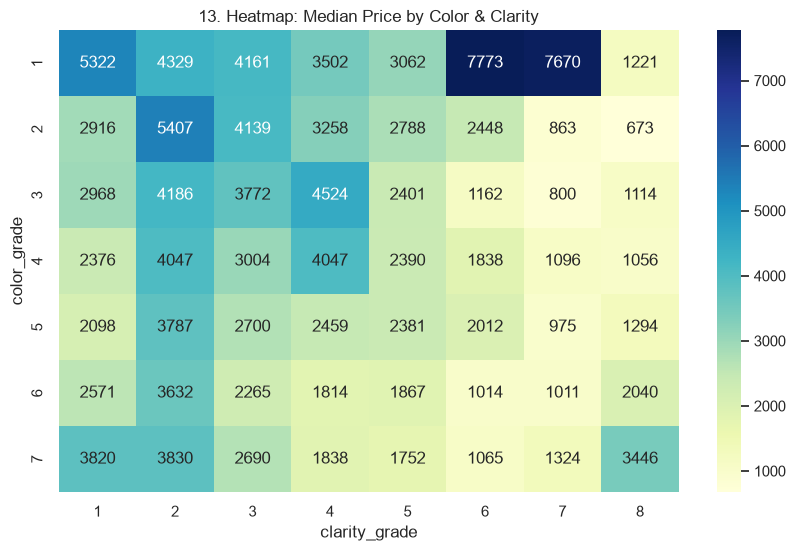

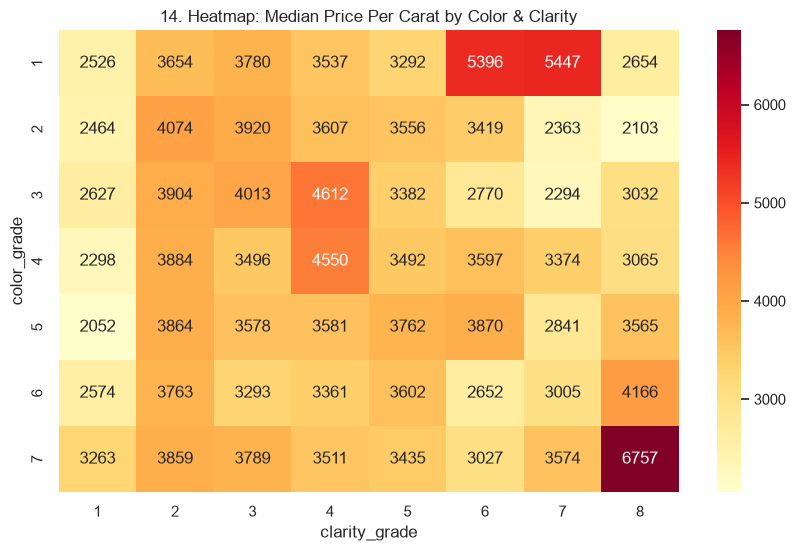

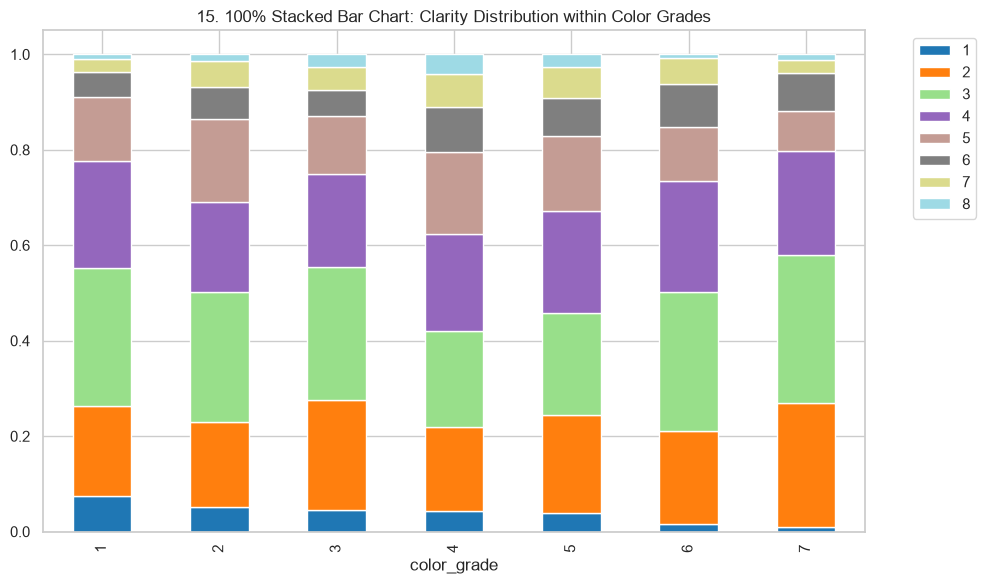

Generating Group D: Geometry & Proportions...


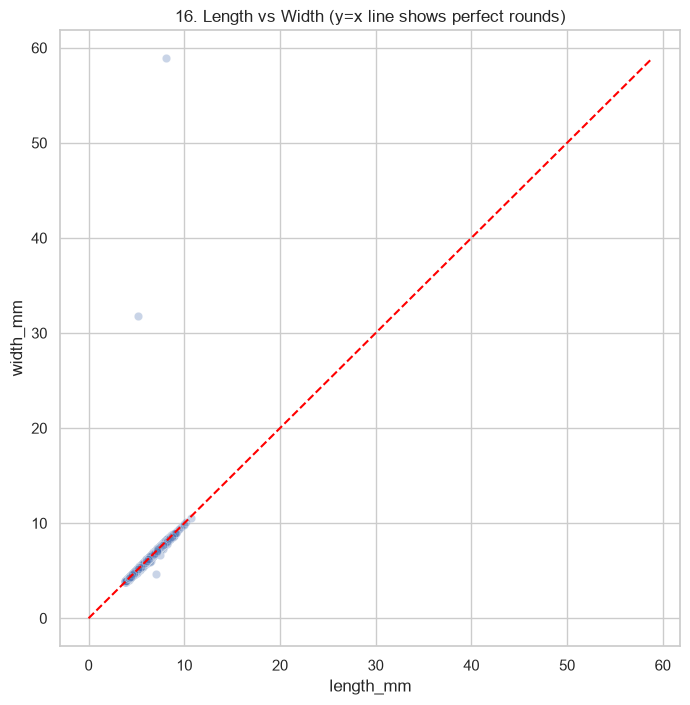

C:\Users\User\AppData\Local\Temp\ipykernel_24704\175718837.py:178: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='shape_category', y='price_per_carat', data=df, palette='Set3')


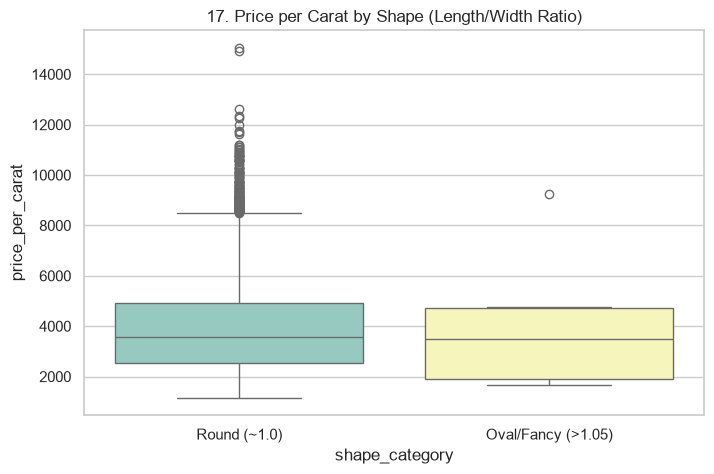

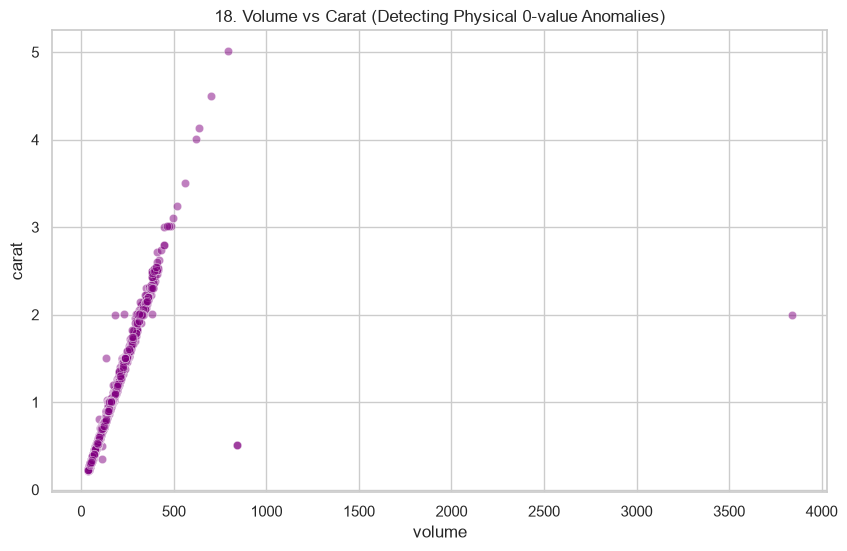

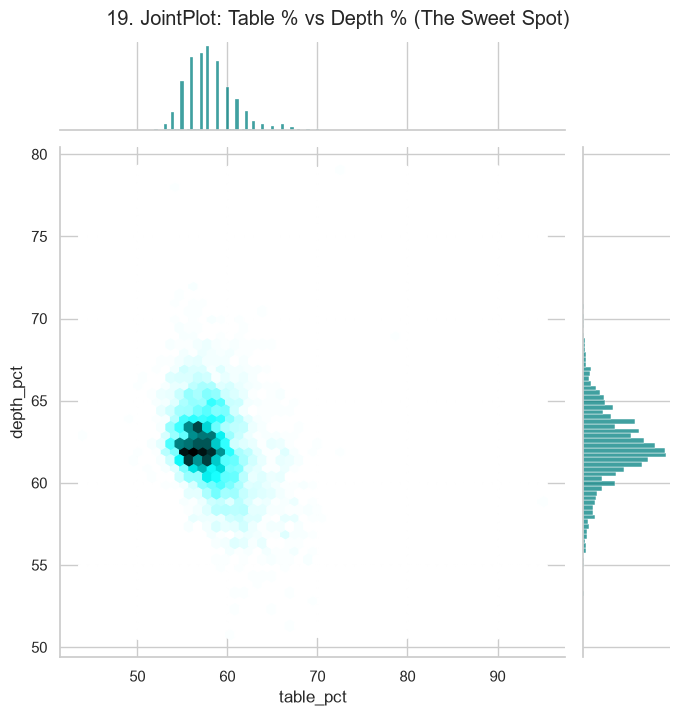

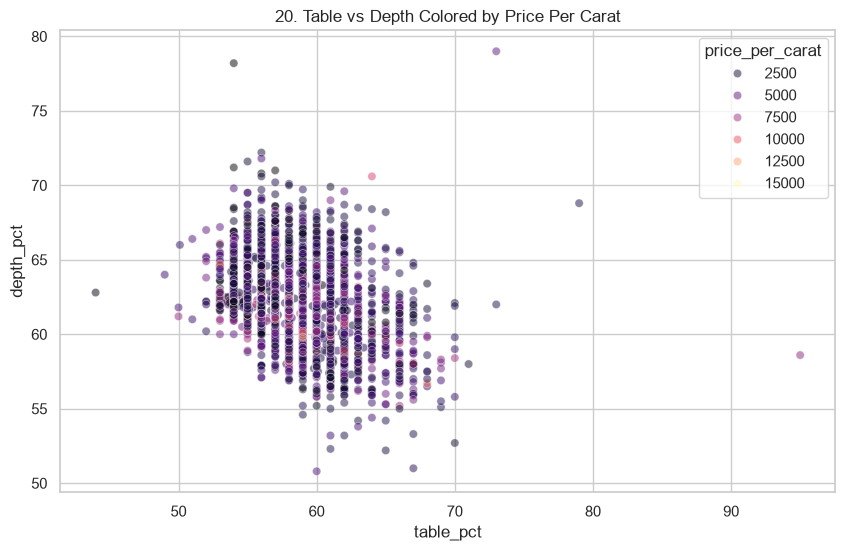

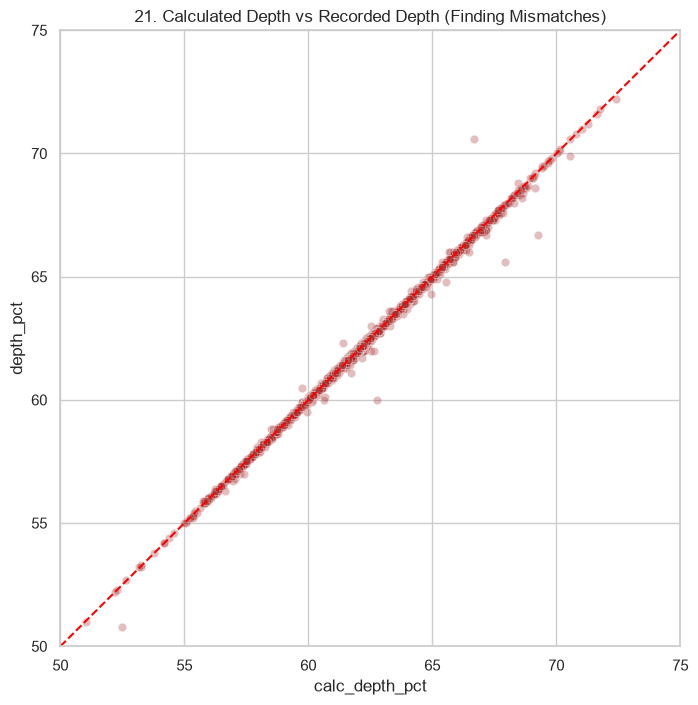

Generating Group E: Multi-dimensional Prep...


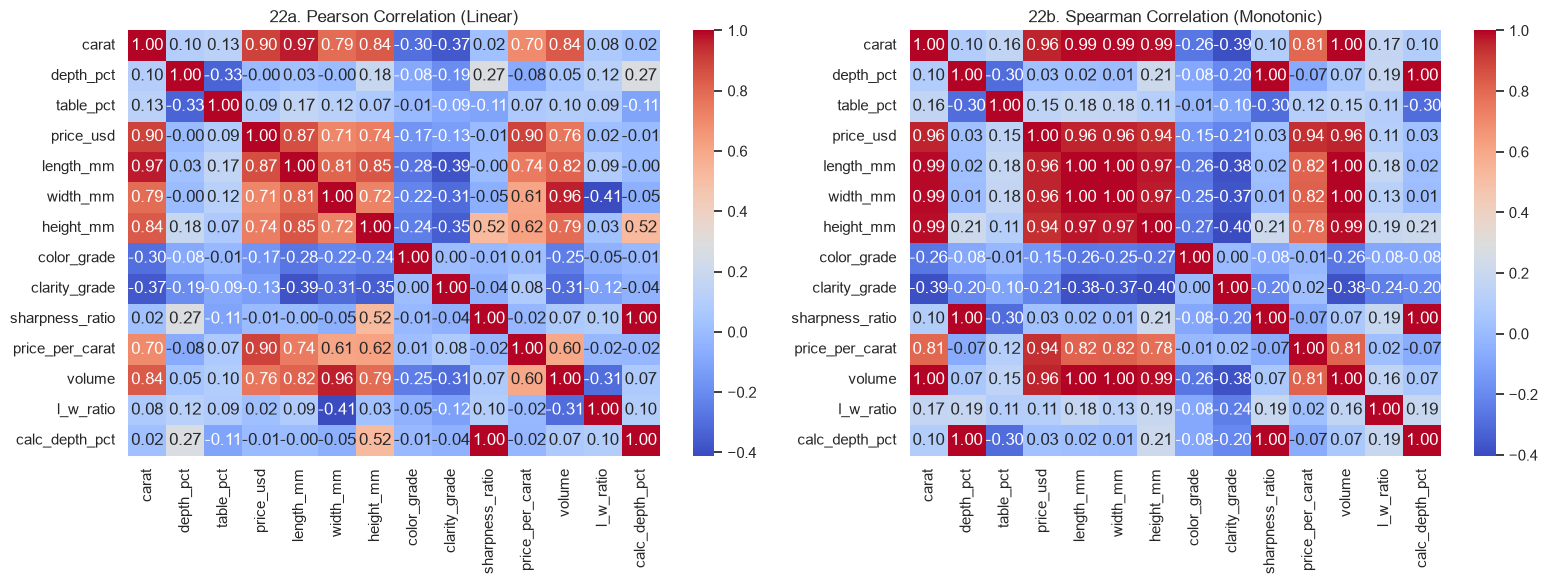

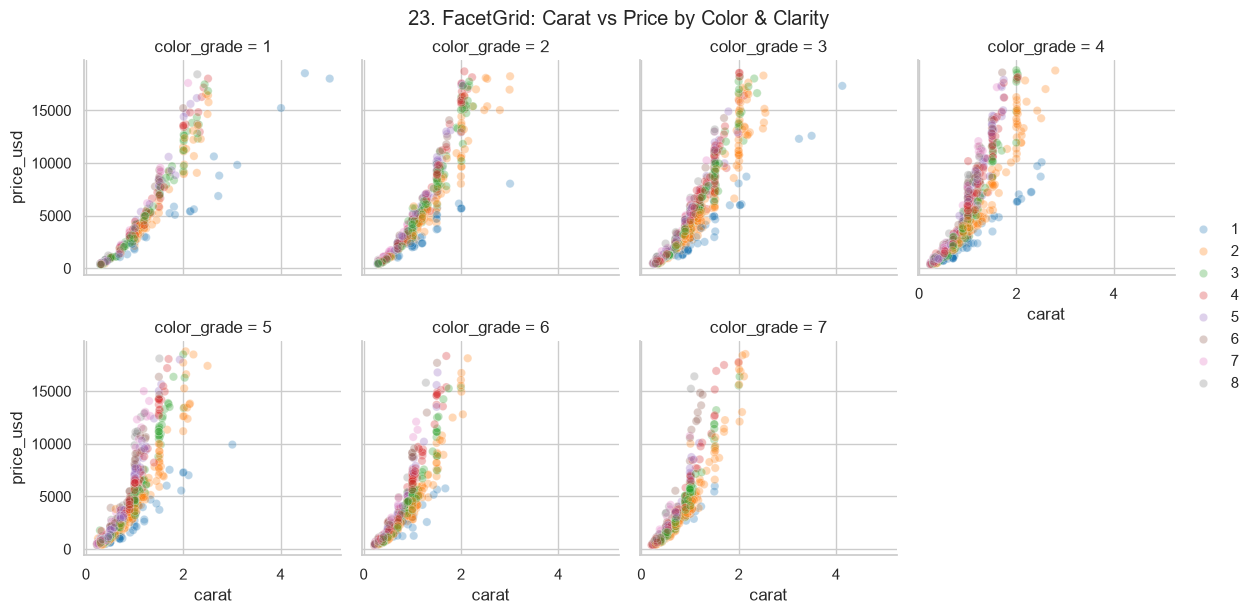

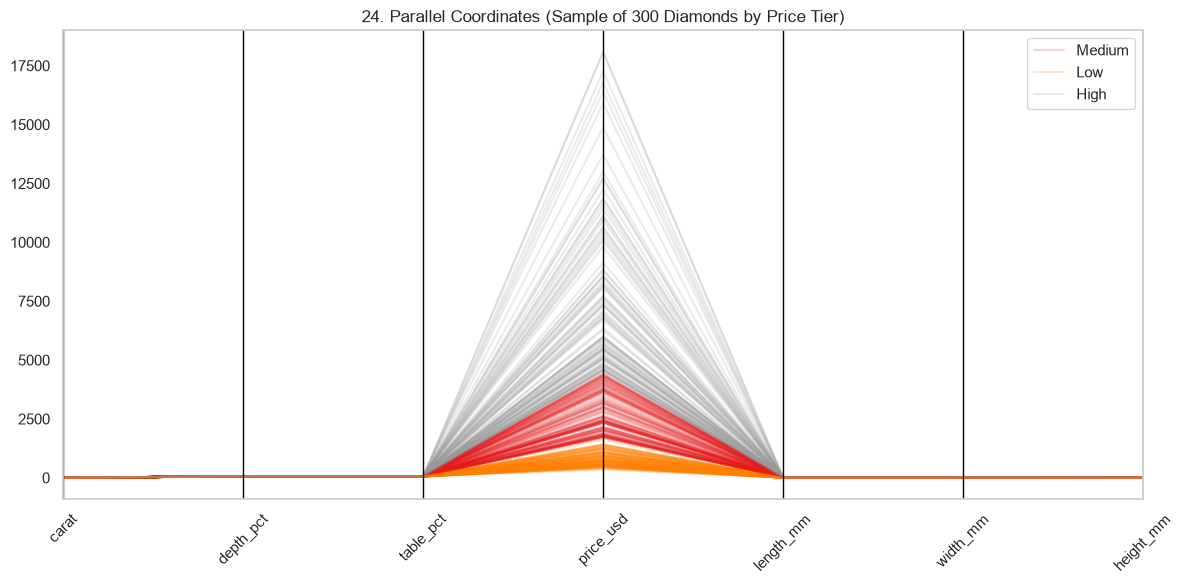

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import parallel_coordinates

# Set style for all plots
sns.set_theme(style="whitegrid")

# ==========================================
# 0. Data Setup & Feature Engineering
# ==========================================


# Drop ID if it exists
if 'diamond_id' in df.columns:
    df = df.drop(columns=['diamond_id'])

# Create required calculated columns for the graphs
df['price_per_carat'] = df['price_usd'] / df['carat']
df['volume'] = df['length_mm'] * df['width_mm'] * df['height_mm']
df['l_w_ratio'] = df['length_mm'] / df['width_mm'].replace(0, np.nan) # Avoid division by zero
df['calc_depth_pct'] = (200 * df['height_mm']) / (df['length_mm'] + df['width_mm']).replace(0, np.nan)

# Create a categorization for Length/Width ratio for Graph 17
df['shape_category'] = pd.cut(df['l_w_ratio'], bins=[0, 1.05, 10], labels=['Round (~1.0)', 'Oval/Fancy (>1.05)'])

# Sort categories for consistency
if 'color_grade' in df.columns:
    color_order = sorted(df['color_grade'].dropna().unique())
if 'clarity_grade' in df.columns:
    clarity_order = sorted(df['clarity_grade'].dropna().unique())


# ==========================================
# GROUP A: 1D Distributions (Graphs 1-3)
# ==========================================
print("Generating Group A: 1D Distributions...")

# Graph 1: 9 Regular Histograms / Countplots
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('1. Basic Distributions of All Features', fontsize=16)
numeric_cols = ['carat', 'depth_pct', 'table_pct', 'price_usd', 'length_mm', 'width_mm', 'height_mm']
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=50, ax=axes[i//3, i%3], color='skyblue')
sns.countplot(data=df, x='color_grade', ax=axes[2, 1], order=color_order, palette='viridis')
sns.countplot(data=df, x='clarity_grade', ax=axes[2, 2], order=clarity_order, palette='viridis')
plt.tight_layout()
plt.show()

# Graph 2: Zoom-in Histogram on Carat (0.2 - 2.2)
plt.figure(figsize=(10, 5))
sns.histplot(df[(df['carat'] >= 0.2) & (df['carat'] <= 2.2)]['carat'], bins=200, color='darkblue')
plt.title('2. Zoom-in on Carat (Psychological Magic Numbers)')
plt.show()

# Graph 3: Log-Scale Price Histogram
plt.figure(figsize=(10, 5))
sns.histplot(df['price_usd'], log_scale=True, bins=50, color='green')
plt.title('3. Log-Scale Price Distribution (Segments of Luxury)')
plt.show()


# ==========================================
# GROUP B: Carat vs Price (Graphs 4-9)
# ==========================================
print("Generating Group B: Carat vs Price...")

# Graph 4: Scatter Carat vs Price + Power Law Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(x='carat', y='price_usd', data=df, alpha=0.1, color='gray')
x_vals = np.linspace(df['carat'].min(), df['carat'].max(), 100)
y_vals = 4325 * (x_vals ** 1.63)
plt.plot(x_vals, y_vals, color='red', linewidth=2, label='Price = 4325 * Carat^1.63')
plt.title('4. Carat vs Price with Power Law Curve')
plt.legend()
plt.show()

# Graph 5: Log-Log Scatter
plt.figure(figsize=(10, 6))
log_carat = np.log10(df['carat'])
log_price = np.log10(df['price_usd'])
sns.regplot(x=log_carat, y=log_price, scatter_kws={'alpha':0.1}, line_kws={'color':'red'})
plt.title('5. Log-Log Scatter: log(Carat) vs log(Price)')
plt.xlabel('log10(Carat)')
plt.ylabel('log10(Price)')
plt.show()

# Graph 6: Carat vs Price by Clarity
plt.figure(figsize=(10, 6))
sns.scatterplot(x='carat', y='price_usd', hue='clarity_grade', data=df, alpha=0.3, hue_order=clarity_order, palette='Set1')
plt.title('6. Carat vs Price Colored by Clarity Grade')
plt.show()

# Graph 7: Carat vs Price by Color
plt.figure(figsize=(10, 6))
sns.scatterplot(x='carat', y='price_usd', hue='color_grade', data=df, alpha=0.3, hue_order=color_order, palette='Set2')
plt.title('7. Carat vs Price Colored by Color Grade')
plt.show()

# Graph 8: Hexbin / 2D Density of Carat vs Price
plt.figure(figsize=(9, 7))
plt.hexbin(df['carat'], df['price_usd'], gridsize=40, cmap='Blues', bins='log')
plt.colorbar(label='log10(count)')
plt.title('8. Hexbin Density Plot of Carat vs Price')
plt.xlabel('Carat')
plt.ylabel('Price (USD)')
plt.show()

# Graph 9: Carat vs Price per Carat
plt.figure(figsize=(10, 6))
sns.regplot(x='carat', y='price_per_carat', data=df, scatter_kws={'alpha':0.1}, line_kws={'color':'red'})
plt.title('9. Carat vs Price Per Carat (The Premium for Size)')
plt.show()


# ==========================================
# GROUP C: Color & Clarity Paradoxes (Graphs 10-15)
# ==========================================
print("Generating Group C: Color & Clarity Paradoxes...")

# Graph 10: Boxen Plot Price by Color
plt.figure(figsize=(10, 5))
sns.boxenplot(x='color_grade', y='price_usd', data=df, order=color_order, palette='coolwarm')
plt.title('10. Boxen Plot: Price by Color Grade')
plt.show()

# Graph 11: Boxen Plot Price by Clarity
plt.figure(figsize=(10, 5))
sns.boxenplot(x='clarity_grade', y='price_usd', data=df, order=clarity_order, palette='viridis')
plt.title('11. Boxen Plot: Price by Clarity Grade')
plt.show()

# Graph 12: Violin Plot Carat by Clarity
plt.figure(figsize=(12, 6))
sns.violinplot(x='clarity_grade', y='carat', data=df, order=clarity_order, palette='muted')
plt.title('12. Violin Plot: Carat vs Clarity (The Flaw/Size Paradox)')
plt.show()

# Graph 13: Heatmap Median Price (Color x Clarity)
plt.figure(figsize=(10, 6))
pivot_price = df.pivot_table(index='color_grade', columns='clarity_grade', values='price_usd', aggfunc='median')
sns.heatmap(pivot_price, annot=True, fmt=".0f", cmap='YlGnBu')
plt.title('13. Heatmap: Median Price by Color & Clarity')
plt.show()

# Graph 14: Heatmap Median Price Per Carat (Color x Clarity)
plt.figure(figsize=(10, 6))
pivot_ppc = df.pivot_table(index='color_grade', columns='clarity_grade', values='price_per_carat', aggfunc='median')
sns.heatmap(pivot_ppc, annot=True, fmt=".0f", cmap='YlOrRd')
plt.title('14. Heatmap: Median Price Per Carat by Color & Clarity')
plt.show()

# Graph 15: 100% Stacked Bar Chart (Color vs Clarity)
crosstab = pd.crosstab(df['color_grade'], df['clarity_grade'], normalize='index')
crosstab.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('15. 100% Stacked Bar Chart: Clarity Distribution within Color Grades')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# ==========================================
# GROUP D: Geometry, Proportions & Outliers (Graphs 16-21)
# ==========================================
print("Generating Group D: Geometry & Proportions...")

# Graph 16: Length vs Width + y=x line
plt.figure(figsize=(8, 8))
sns.scatterplot(x='length_mm', y='width_mm', data=df, alpha=0.3)
max_dim = max(df['length_mm'].max(), df['width_mm'].max())
plt.plot([0, max_dim], [0, max_dim], color='red', linestyle='--')
plt.title('16. Length vs Width (y=x line shows perfect rounds)')
plt.show()

# Graph 17: Boxplot of L/W Ratio vs Price per Carat
plt.figure(figsize=(8, 5))
sns.boxplot(x='shape_category', y='price_per_carat', data=df, palette='Set3')
plt.title('17. Price per Carat by Shape (Length/Width Ratio)')
plt.show()

# Graph 18: Anomaly Plot - Volume vs Carat
plt.figure(figsize=(10, 6))
sns.scatterplot(x='volume', y='carat', data=df, color='purple', alpha=0.5)
plt.title('18. Volume vs Carat (Detecting Physical 0-value Anomalies)')
plt.show()

# Graph 19: JointPlot Table vs Depth
sns.jointplot(x='table_pct', y='depth_pct', data=df, kind='hex', color='teal', height=7)
plt.suptitle('19. JointPlot: Table % vs Depth % (The Sweet Spot)', y=1.02)
plt.show()

# Graph 20: Table vs Depth colored by Price Per Carat
plt.figure(figsize=(10, 6))
sns.scatterplot(x='table_pct', y='depth_pct', hue='price_per_carat', data=df, palette='magma', alpha=0.5)
plt.title('20. Table vs Depth Colored by Price Per Carat')
plt.show()

# Graph 21: Calculated Depth vs Recorded Depth
plt.figure(figsize=(8, 8))
sns.scatterplot(x='calc_depth_pct', y='depth_pct', data=df, alpha=0.3, color='brown')
plt.plot([50, 75], [50, 75], color='red', linestyle='--')
plt.title('21. Calculated Depth vs Recorded Depth (Finding Mismatches)')
plt.xlim(50, 75)
plt.ylim(50, 75)
plt.show()


# ==========================================
# GROUP E: Clustering Prep (Graphs 22-24)
# ==========================================
print("Generating Group E: Multi-dimensional Prep...")

# Graph 22: Pearson vs Spearman Heatmap
numeric_df = df.select_dtypes(include=[np.number])
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(numeric_df.corr(method='pearson'), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0])
axes[0].set_title('22a. Pearson Correlation (Linear)')
sns.heatmap(numeric_df.corr(method='spearman'), annot=True, fmt=".2f", cmap='coolwarm', ax=axes[1])
axes[1].set_title('22b. Spearman Correlation (Monotonic)')
plt.tight_layout()
plt.show()

# Graph 23: FacetGrid (Color -> Clarity, Carat vs Price)
g = sns.FacetGrid(df, col='color_grade', col_wrap=4, height=3)
g.map_dataframe(sns.scatterplot, x='carat', y='price_usd', hue='clarity_grade', alpha=0.3, palette='tab10')
g.add_legend()
g.fig.suptitle('23. FacetGrid: Carat vs Price by Color & Clarity', y=1.02)
plt.show()

# Graph 24: Parallel Coordinates (Subset to avoid freezing)
plt.figure(figsize=(12, 6))
# Creating price tiers for color coding
df['price_tier'] = pd.qcut(df['price_usd'], q=3, labels=['Low', 'Medium', 'High'])
# Take a random sample of 300 to make the graph readable
sample_df = df.dropna().sample(n=300, random_state=42)
parallel_cols = ['carat', 'depth_pct', 'table_pct', 'price_usd', 'length_mm', 'width_mm', 'height_mm', 'price_tier']
parallel_coordinates(sample_df[parallel_cols], 'price_tier', colormap='Set1', alpha=0.2)
plt.title('24. Parallel Coordinates (Sample of 300 Diamonds by Price Tier)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# PCA

### Creating the following datasets
#### Our Question - We decided to answer the following question:

Is there a price difference between the physical attributes (height, length, width, carat) to propotional attributes ( table_pct, depth_pct, clarity_grade, color_grade).

In [ ]:
# Firstly we create the data frames
# Physical Attributes DataFrame
physical_cols = ['carat', 'length_mm', 'width_mm', 'height_mm']
physical_df = df[physical_cols].copy()

# Proportional & Quality Attributes DataFrame
proportional_cols = ['table_pct', 'depth_pct', 'color_grade', 'clarity_grade']
proportional_df = df[proportional_cols].copy()

# Combined DataFrame (Physical + Proportional)
combined_cols = physical_cols + proportional_cols
combined_df = df[combined_cols].copy()

# Print shapes to verify
print(f"Physical DataFrame shape: {physical_df.shape}")
print(f"Proportional DataFrame shape: {proportional_df.shape}")
print(f"Combined DataFrame shape: {combined_df.shape}")

Physical DataFrame shape: (5010, 4)
Proportional DataFrame shape: (5010, 4)
Combined DataFrame shape: (5010, 8)


#### Encoding our data, (Color,Clarity) mapping

In [89]:
import pandas as pd

# 1. Create the separated dataframes
physical_cols = ['carat', 'length_mm', 'width_mm', 'height_mm']
proportional_cols = ['table_pct', 'depth_pct', 'color_grade', 'clarity_grade']

physical_df = df[physical_cols].copy()
proportional_df = df[proportional_cols].copy()
combined_df = df[physical_cols + proportional_cols].copy()

# 2. Convert the string numbers ('1', '2', etc.) into actual math numbers
proportional_df['color_grade'] = pd.to_numeric(proportional_df['color_grade'], errors='coerce')
proportional_df['clarity_grade'] = pd.to_numeric(proportional_df['clarity_grade'], errors='coerce')

combined_df['color_grade'] = pd.to_numeric(combined_df['color_grade'], errors='coerce')
combined_df['clarity_grade'] = pd.to_numeric(combined_df['clarity_grade'], errors='coerce')

# 3. Drop any actual missing values to create the final "Clean" versions
physical_clean = physical_df.dropna()
proportional_clean = proportional_df.dropna()
combined_clean = combined_df.dropna()

print("--- Shapes After Cleaning ---")
print(f"Physical Clean Shape: {physical_clean.shape}")
print(f"Proportional Clean Shape: {proportional_clean.shape}")
print(f"Combined Clean Shape: {combined_clean.shape}")

--- Shapes After Cleaning ---
Physical Clean Shape: (5010, 4)
Proportional Clean Shape: (4980, 4)
Combined Clean Shape: (4980, 8)


#### Scaling our data using Standard Scaler

In [90]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scale the data (this outputs numpy arrays, not pandas dataframes)
physical_scaled = scaler.fit_transform(physical_clean)
proportional_scaled = scaler.fit_transform(proportional_clean)
combined_scaled = scaler.fit_transform(combined_clean)

print("--- Shapes After Scaling ---")
print(f"Physical Scaled Shape: {physical_scaled.shape}")
print(f"Proportional Scaled Shape: {proportional_scaled.shape}")
print(f"Combined Scaled Shape: {combined_scaled.shape}")

--- Shapes After Scaling ---
Physical Scaled Shape: (5010, 4)
Proportional Scaled Shape: (4980, 4)
Combined Scaled Shape: (4980, 8)


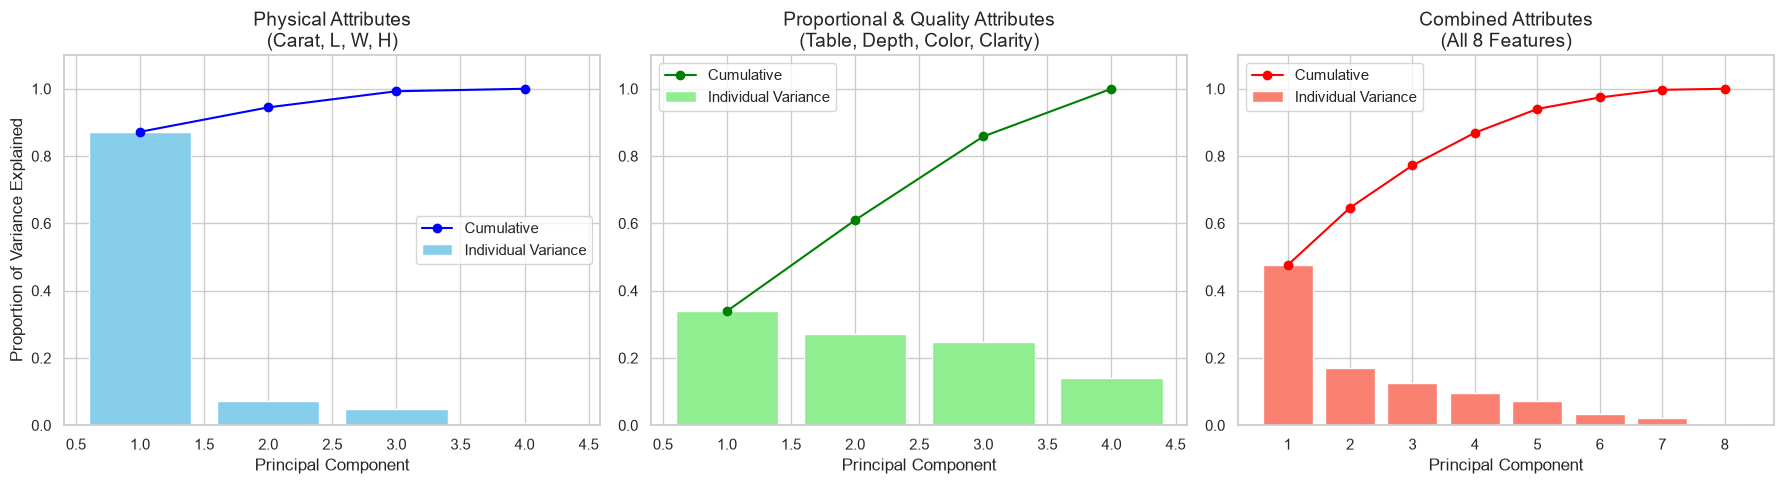

In [ ]:
from sklearn.decomposition import PCA

# 1. Fit PCA models
pca_physical = PCA().fit(physical_scaled)
pca_proportional = PCA().fit(proportional_scaled)
pca_combined = PCA().fit(combined_scaled)

# 2. Plotting setup
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graph 1: Physical Attributes
axes[0].bar(range(1, len(pca_physical.explained_variance_ratio_) + 1), 
            pca_physical.explained_variance_ratio_, color='skyblue', label='Individual Variance')
axes[0].plot(range(1, len(pca_physical.explained_variance_ratio_) + 1), 
             pca_physical.explained_variance_ratio_.cumsum(), color='blue', marker='o', label='Cumulative')
axes[0].set_title('Physical Attributes\n(Carat, L, W, H)', fontsize=14)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Proportion of Variance Explained')
axes[0].set_ylim(0, 1.1)
axes[0].legend()

# Graph 2: Proportional Attributes
axes[1].bar(range(1, len(pca_proportional.explained_variance_ratio_) + 1), 
            pca_proportional.explained_variance_ratio_, color='lightgreen', label='Individual Variance')
axes[1].plot(range(1, len(pca_proportional.explained_variance_ratio_) + 1), 
             pca_proportional.explained_variance_ratio_.cumsum(), color='green', marker='o', label='Cumulative')
axes[1].set_title('Proportional & Quality Attributes\n(Table, Depth, Color, Clarity)', fontsize=14)
axes[1].set_xlabel('Principal Component')
axes[1].set_ylim(0, 1.1)
axes[1].legend()

# Graph 3: Combined Attributes
axes[2].bar(range(1, len(pca_combined.explained_variance_ratio_) + 1), 
            pca_combined.explained_variance_ratio_, color='salmon', label='Individual Variance')
axes[2].plot(range(1, len(pca_combined.explained_variance_ratio_) + 1), 
             pca_combined.explained_variance_ratio_.cumsum(), color='red', marker='o', label='Cumulative')
axes[2].set_title('Combined Attributes\n(All 8 Features)', fontsize=14)
axes[2].set_xlabel('Principal Component')
axes[2].set_ylim(0, 1.1)
axes[2].legend()

plt.tight_layout()
plt.show()

#### Physical Attributes (Left Graph - Blue):
 The first principal component (PC1) alone captures roughly 85% to 90% of the total variance. This happens because carat weight, length, width, and height are practically perfectly correlated; they all measure the exact same underlying concept of "Size". The graph confirms that you could compress these four physical dimensions into a single variable without losing much meaningful information.

#### Proportional Attributes (Mid graph - Green)
Unlike the physical traits, the variance here is spread much more evenly across all four components, with PC1 capturing only about 35% of the information. The cumulative variance line climbs steadily like a staircase. This proves that table percentage, depth percentage, color, and clarity are largely independent of one another. A diamond's color doesn't dictate its table cut, so PCA cannot easily compress them into a single dimension.

#### Combined Attributes (Right Graph - Red):
 When you put all 8 features together, PC1 captures just under 50% of the variance. This dominant first component is almost certainly representing the massive "Size" factor carried over from the physical attributes. The subsequent components (PC2, PC3, etc.) gradually add the remaining independent information from the quality and proportion metrics, taking about 3 or 4 components to surpass 80% cumulative variance.

Running NMF for all 3 dataframes...
Running t-SNE for all 3 dataframes... (This will take a minute)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


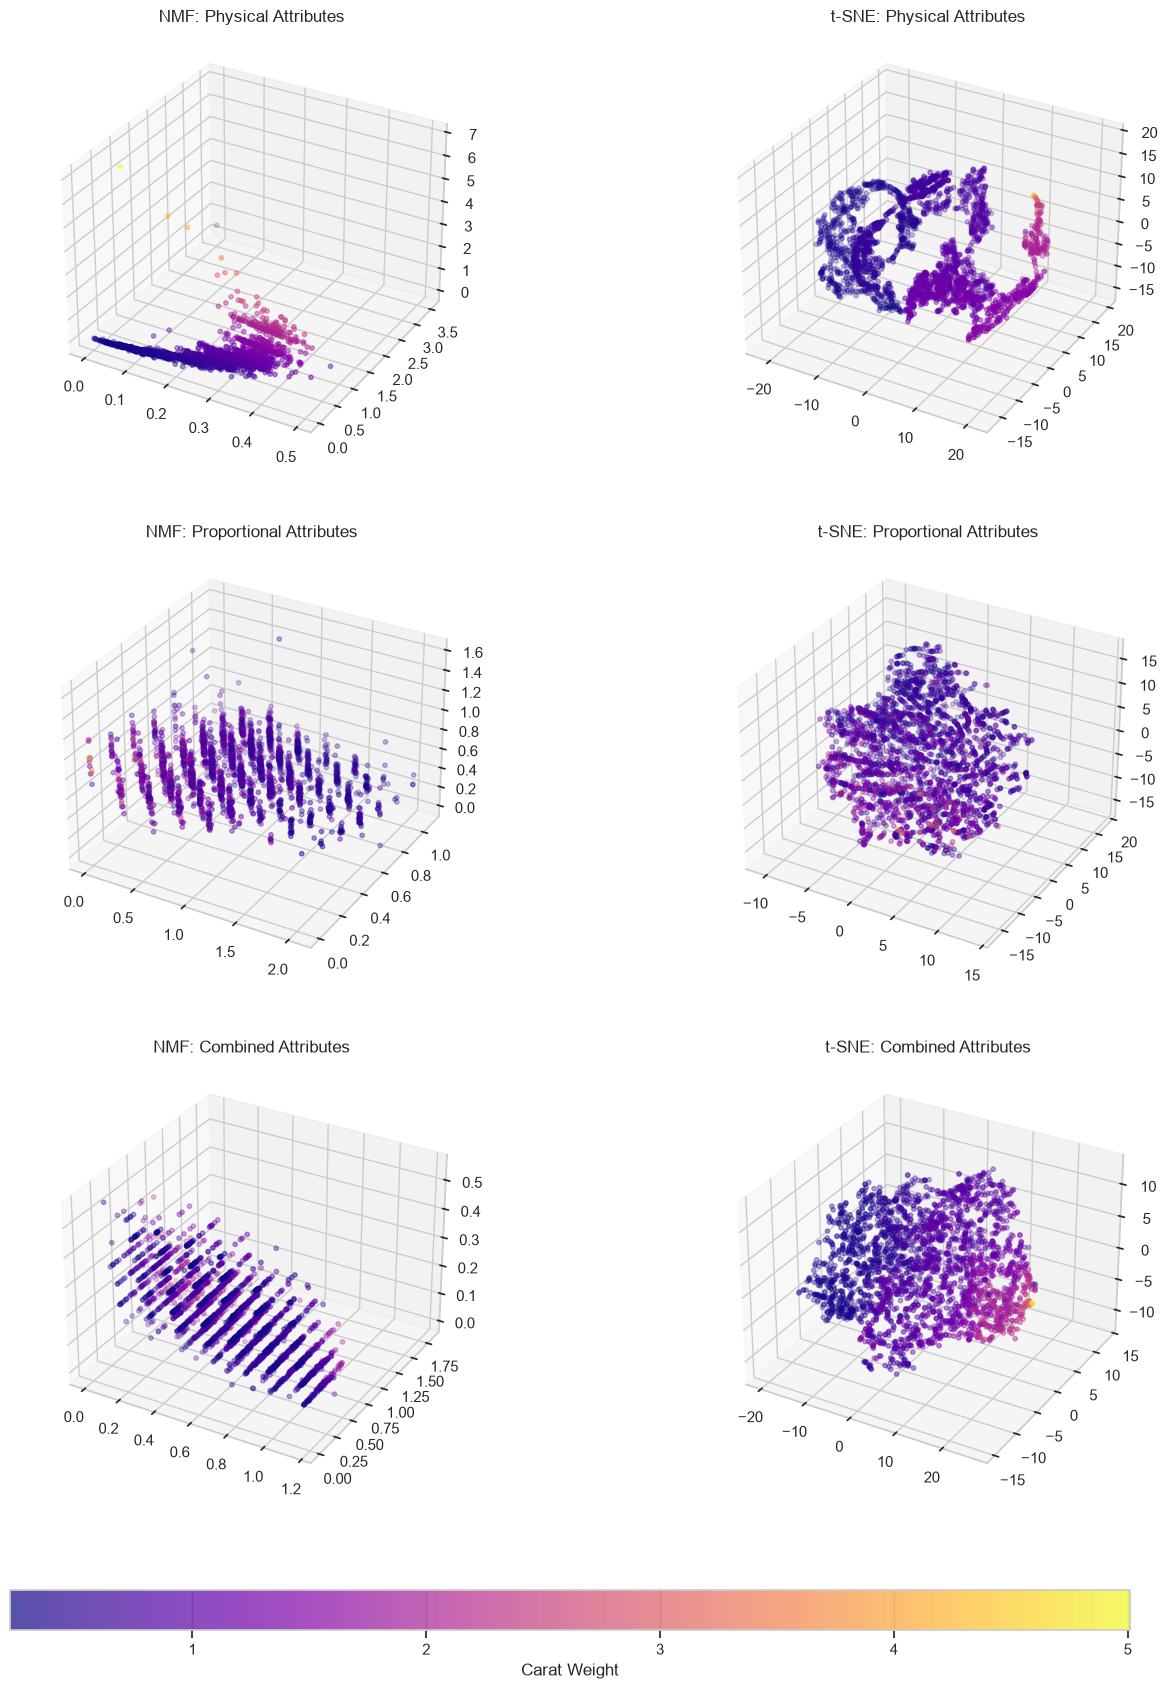

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import NMF
from sklearn.manifold import TSNE

# 1. Take ONE aligned sample so the data matches across all tests
sample_size = 3000
df_sample = df.dropna().sample(n=sample_size, random_state=42)

# Re-create the 3 dataframes from the sample (FIXED COLUMN NAMES)
physical_sample = df_sample[['carat', 'length_mm', 'width_mm', 'height_mm']]
proportional_sample = df_sample[['table_pct', 'depth_pct', 'color_grade', 'clarity_grade']]
combined_sample = df_sample[['carat', 'length_mm', 'width_mm', 'height_mm', 'table_pct', 'depth_pct', 'color_grade', 'clarity_grade']]

# 2. Setup Scalers
minmax = MinMaxScaler()
std = StandardScaler()

# 3. Run NMF (Requires MinMax scaled data)
print("Running NMF for all 3 dataframes...")
nmf = NMF(n_components=3, init='random', random_state=42, max_iter=500)

nmf_phys = nmf.fit_transform(minmax.fit_transform(physical_sample))
nmf_prop = nmf.fit_transform(minmax.fit_transform(proportional_sample))
nmf_comb = nmf.fit_transform(minmax.fit_transform(combined_sample))

# 4. Run t-SNE (Requires Standard scaled data)
print("Running t-SNE for all 3 dataframes... (This will take a minute)")
tsne = TSNE(n_components=3, random_state=42, perplexity=30)

tsne_phys = tsne.fit_transform(std.fit_transform(physical_sample))
tsne_prop = tsne.fit_transform(std.fit_transform(proportional_sample))
tsne_comb = tsne.fit_transform(std.fit_transform(combined_sample))

# 5. Visualize everything in a 3x2 Grid
fig = plt.figure(figsize=(16, 20))
titles = ['Physical Attributes', 'Proportional Attributes', 'Combined Attributes']
nmf_data = [nmf_phys, nmf_prop, nmf_comb]
tsne_data = [tsne_phys, tsne_prop, tsne_comb]

# Plotting manually to avoid complex loops
# Row 1: Physical
ax1 = fig.add_subplot(3, 2, 1, projection='3d')
ax1.scatter(nmf_phys[:, 0], nmf_phys[:, 1], nmf_phys[:, 2], c=df_sample['carat'], cmap='plasma', s=10, alpha=0.7)
ax1.set_title('NMF: Physical Attributes')

ax2 = fig.add_subplot(3, 2, 2, projection='3d')
ax2.scatter(tsne_phys[:, 0], tsne_phys[:, 1], tsne_phys[:, 2], c=df_sample['carat'], cmap='plasma', s=10, alpha=0.7)
ax2.set_title('t-SNE: Physical Attributes')

# Row 2: Proportional
ax3 = fig.add_subplot(3, 2, 3, projection='3d')
ax3.scatter(nmf_prop[:, 0], nmf_prop[:, 1], nmf_prop[:, 2], c=df_sample['carat'], cmap='plasma', s=10, alpha=0.7)
ax3.set_title('NMF: Proportional Attributes')

ax4 = fig.add_subplot(3, 2, 4, projection='3d')
ax4.scatter(tsne_prop[:, 0], tsne_prop[:, 1], tsne_prop[:, 2], c=df_sample['carat'], cmap='plasma', s=10, alpha=0.7)
ax4.set_title('t-SNE: Proportional Attributes')

# Row 3: Combined
ax5 = fig.add_subplot(3, 2, 5, projection='3d')
ax5.scatter(nmf_comb[:, 0], nmf_comb[:, 1], nmf_comb[:, 2], c=df_sample['carat'], cmap='plasma', s=10, alpha=0.7)
ax5.set_title('NMF: Combined Attributes')

ax6 = fig.add_subplot(3, 2, 6, projection='3d')
scatter_final = ax6.scatter(tsne_comb[:, 0], tsne_comb[:, 1], tsne_comb[:, 2], c=df_sample['carat'], cmap='plasma', s=10, alpha=0.7)
ax6.set_title('t-SNE: Combined Attributes')

# Add a single colorbar at the bottom
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.02]) # [left, bottom, width, height]
fig.colorbar(scatter_final, cax=cbar_ax, orientation='horizontal', label='Carat Weight')

plt.subplots_adjust(bottom=0.15)
plt.show()

#### NMF (Non-negative Matrix Factorization)
NMF is a strict, linear algorithm that tries to organize the data using simple, straight-line rules. Because our dataset contains rigid numbered categories (like clarity grades 1 through 8), NMF forces the diamonds into harsh, parallel "lanes" or stripes. It treats the diamond market like a rigid mathematical grid, failing to capture the natural, organic variations between the individual stones.

#### t-SNE (t-Distributed Stochastic Neighbor Embedding)
t-SNE acts more like a matchmaker, ignoring strict straight lines and simply trying to place similar diamonds close together while pushing different ones apart. This creates a natural, continuous cloud, which accurately reflects that the diamond market is a smooth spectrum with no massive gaps. By successfully grouping the rare, heavy diamonds (the bright yellow dots) into their own distinct neighborhood on the edge, t-SNE proves it understands the true, organic relationships in your data.

# Clutstering

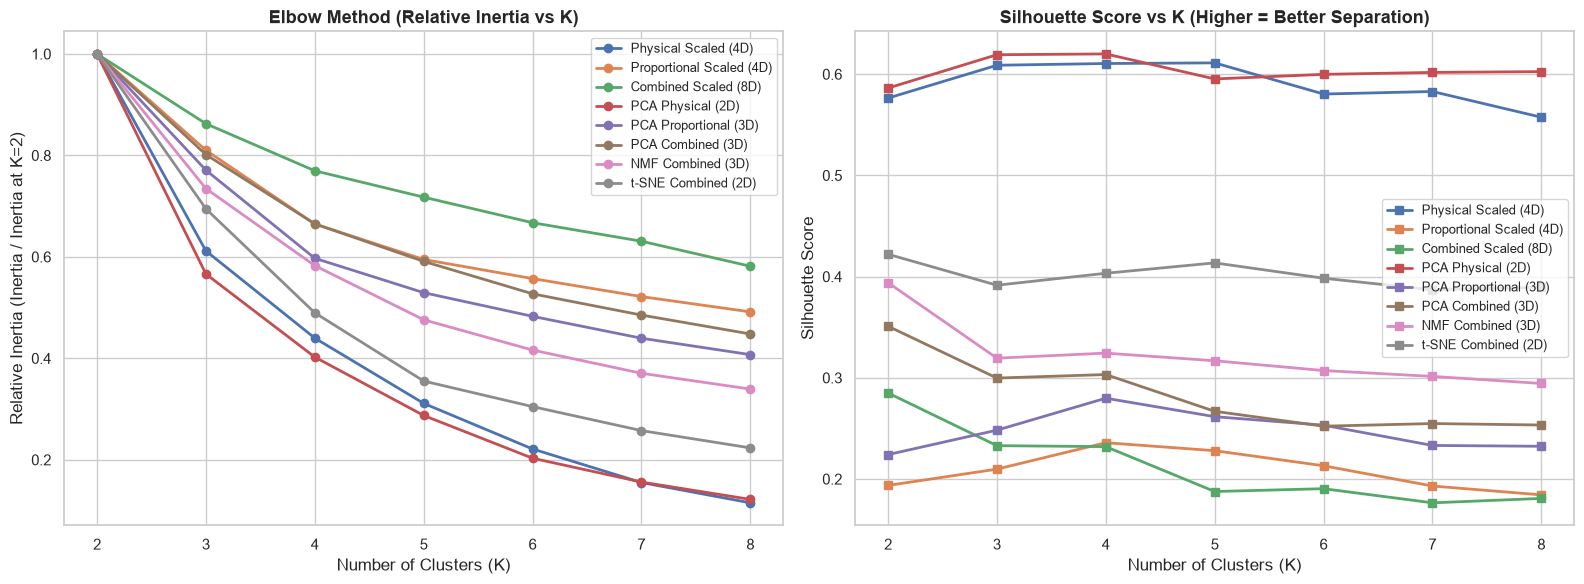

=== סיכום ביצועי K-Means (K=3) על כל הייצוגים ===
                   Space  K  Silhouette  Davies_Bouldin
    Physical Scaled (4D)  3       0.609           0.544
Proportional Scaled (4D)  3       0.210           1.484
    Combined Scaled (8D)  3       0.233           1.530
       PCA Physical (2D)  3       0.619           0.521
   PCA Proportional (3D)  3       0.248           1.317
       PCA Combined (3D)  3       0.300           1.237
       NMF Combined (3D)  3       0.319           1.079
     t-SNE Combined (2D)  3       0.391           0.891


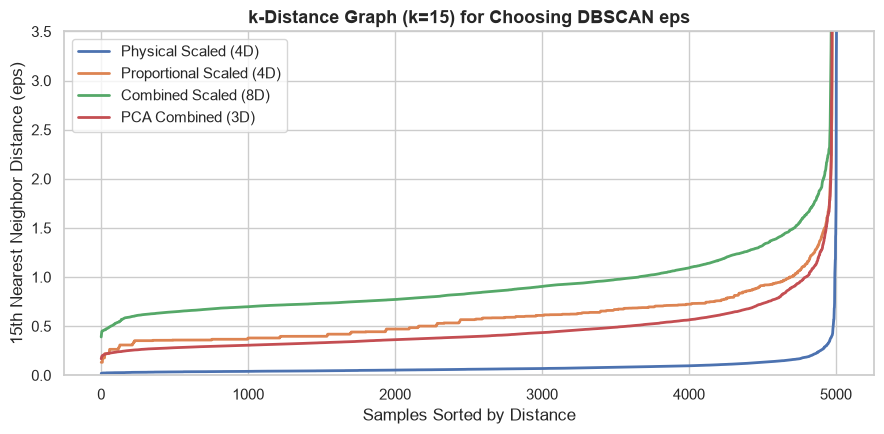


=== סיכום ביצועי DBSCAN על המרחבים השונים ===
                       Space  eps  min_samples  Clusters_Found  Noise_% Silhouette_NonNoise
        Physical Scaled (4D) 0.25           10               2      0.8                0.53
    Proportional Scaled (4D) 0.80           10               1      4.0                 N/A
        Combined Scaled (8D) 1.00           10               1      8.5                 N/A
Combined Scaled (8D) [tight] 0.80           10               1     21.9                 N/A
           PCA Physical (2D) 0.15           10               2      1.2                0.51
           PCA Combined (3D) 0.55           15               1     10.3                 N/A
           NMF Combined (3D) 0.04           15               1      0.0                 N/A
         t-SNE Combined (2D) 3.50           15              23      3.3              -0.012


In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import NMF
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")

# ==============================================================================
# הכנת הייצוגים לאחר הורדת מימד מתוך המשתנים הקיימים שלך (שלב 2)
# ==============================================================================
X_pca_physical = pca_physical.transform(physical_scaled)[:, :2]         # מעל 99% מהשונות הפיזית
X_pca_proportional = pca_proportional.transform(proportional_scaled)[:, :3]
X_pca_combined = pca_combined.transform(combined_scaled)[:, :3]

# NMF דורש נתונים אי-שליליים (>= 0), לכן ממירים את combined_scaled לטווח [0, 1]
combined_non_neg = MinMaxScaler().fit_transform(combined_scaled)
X_nmf_combined = NMF(n_components=3, random_state=42, max_iter=500).fit_transform(combined_non_neg)

# t-SNE להורדה ל-2 מימדים (אם כבר חישבת משתנה כזה, ניתן להחליף בשם המשתנה שלך)
X_tsne_combined = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(combined_scaled)

# מילון מרכזי של כל המרחבים (מקוריים + הורדות מימד)
spaces = {
    'Physical Scaled (4D)': physical_scaled,
    'Proportional Scaled (4D)': proportional_scaled,
    'Combined Scaled (8D)': combined_scaled,
    'PCA Physical (2D)': X_pca_physical,
    'PCA Proportional (3D)': X_pca_proportional,
    'PCA Combined (3D)': X_pca_combined,
    'NMF Combined (3D)': X_nmf_combined,
    't-SNE Combined (2D)': X_tsne_combined
}

# ==============================================================================
# 3א. K-Means: בחירת מספר אשכולות אופטימלי (Elbow Method + Silhouette Score)
# ==============================================================================
K_range = range(2, 9)
inertias_rel = {name: [] for name in spaces}
silhouettes = {name: [] for name in spaces}

for name, X_data in spaces.items():
    raw_inertia = []
    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_data)
        raw_inertia.append(km.inertia_)
        silhouettes[name].append(silhouette_score(X_data, labels))
    # נרמול Inertia ביחס ל-K=2 כדי שכל העקומות יוצגו על אותה סקאלה ויזואלית
    inertias_rel[name] = [val / raw_inertia[0] for val in raw_inertia]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name in spaces:
    axes[0].plot(K_range, inertias_rel[name], marker='o', lw=2, label=name)
    axes[1].plot(K_range, silhouettes[name], marker='s', lw=2, label=name)

axes[0].set_title('Elbow Method (Relative Inertia vs K)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Relative Inertia (Inertia / Inertia at K=2)')
axes[0].legend(fontsize=9)

axes[1].set_title('Silhouette Score vs K (Higher = Better Separation)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

# הרצת K-Means סופי עם K=3 (נקודת הברך) ושמירת תוויות האשכולות להמשך (שלב 4)
OPTIMAL_K = 3
cluster_labels = {}
kmeans_summary = []

for name, X_data in spaces.items():
    km = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
    labels = km.fit_predict(X_data)
    cluster_labels[f"KM | {name}"] = labels
    
    kmeans_summary.append({
        'Space': name,
        'K': OPTIMAL_K,
        'Silhouette': round(silhouette_score(X_data, labels), 3),
        'Davies_Bouldin': round(davies_bouldin_score(X_data, labels), 3)
    })

print("=== סיכום ביצועי K-Means (K=3) על כל הייצוגים ===")
print(pd.DataFrame(kmeans_summary).to_string(index=False))

# ==============================================================================
# 3ב. DBSCAN: גרף k-Distance לבחירת eps + הרצה על מקורי והורדות מימד
# ==============================================================================
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in ['Physical Scaled (4D)', 'Proportional Scaled (4D)', 'Combined Scaled (8D)', 'PCA Combined (3D)']:
    X_data = spaces[name]
    nn = NearestNeighbors(n_neighbors=15).fit(X_data)
    distances, _ = nn.kneighbors(X_data)
    ax.plot(np.sort(distances[:, -1]), lw=2, label=name)

ax.set_title('k-Distance Graph (k=15) for Choosing DBSCAN eps', fontsize=13, fontweight='bold')
ax.set_xlabel('Samples Sorted by Distance')
ax.set_ylabel('15th Nearest Neighbor Distance (eps)')
ax.set_ylim(0, 3.5)
ax.legend()
plt.tight_layout()
plt.show()

# הגדרת קונפיגורציות DBSCAN מותאמות לכל מרחב
dbscan_configs = [
    ('Physical Scaled (4D)', physical_scaled, 0.25, 10),
    ('Proportional Scaled (4D)', proportional_scaled, 0.80, 10),
    ('Combined Scaled (8D)', combined_scaled, 1.00, 10),
    ('Combined Scaled (8D) [tight]', combined_scaled, 0.80, 10),
    ('PCA Physical (2D)', X_pca_physical, 0.15, 10),
    ('PCA Combined (3D)', X_pca_combined, 0.55, 15),
    ('NMF Combined (3D)', X_nmf_combined, 0.04, 15),
    ('t-SNE Combined (2D)', X_tsne_combined, 3.50, 15)
]

dbscan_summary = []
for space_name, X_data, eps_val, ms_val in dbscan_configs:
    db = DBSCAN(eps=eps_val, min_samples=ms_val)
    labels = db.fit_predict(X_data)
    cluster_labels[f"DBSCAN | {space_name}"] = labels
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    valid_mask = labels != -1
    sil = silhouette_score(X_data[valid_mask], labels[valid_mask]) if n_clusters >= 2 and valid_mask.sum() > 20 else np.nan
    
    dbscan_summary.append({
        'Space': space_name,
        'eps': eps_val,
        'min_samples': ms_val,
        'Clusters_Found': n_clusters,
        'Noise_%': round(noise_pct, 1),
        'Silhouette_NonNoise': round(sil, 3) if not np.isnan(sil) else 'N/A'
    })

print("\n=== סיכום ביצועי DBSCAN על המרחבים השונים ===")
print(pd.DataFrame(dbscan_summary).to_string(index=False))


=== K-Means Performance (K=3) ===
              Space  Silhouette  Davies_Bouldin
      Physical (4D)       0.609           0.544
  Proportional (4D)       0.210           1.484
      Combined (8D)       0.233           1.530
  PCA Combined (3D)       0.300           1.237
t-SNE Combined (2D)       0.391           0.891

=== DBSCAN Performance ===
            Space  eps  Clusters  Noise_%  Silhouette
Proportional (4D) 0.80         1      4.0         NaN
    Combined (8D) 1.00         1      8.5         NaN
PCA Combined (3D) 0.55         1     10.3         NaN


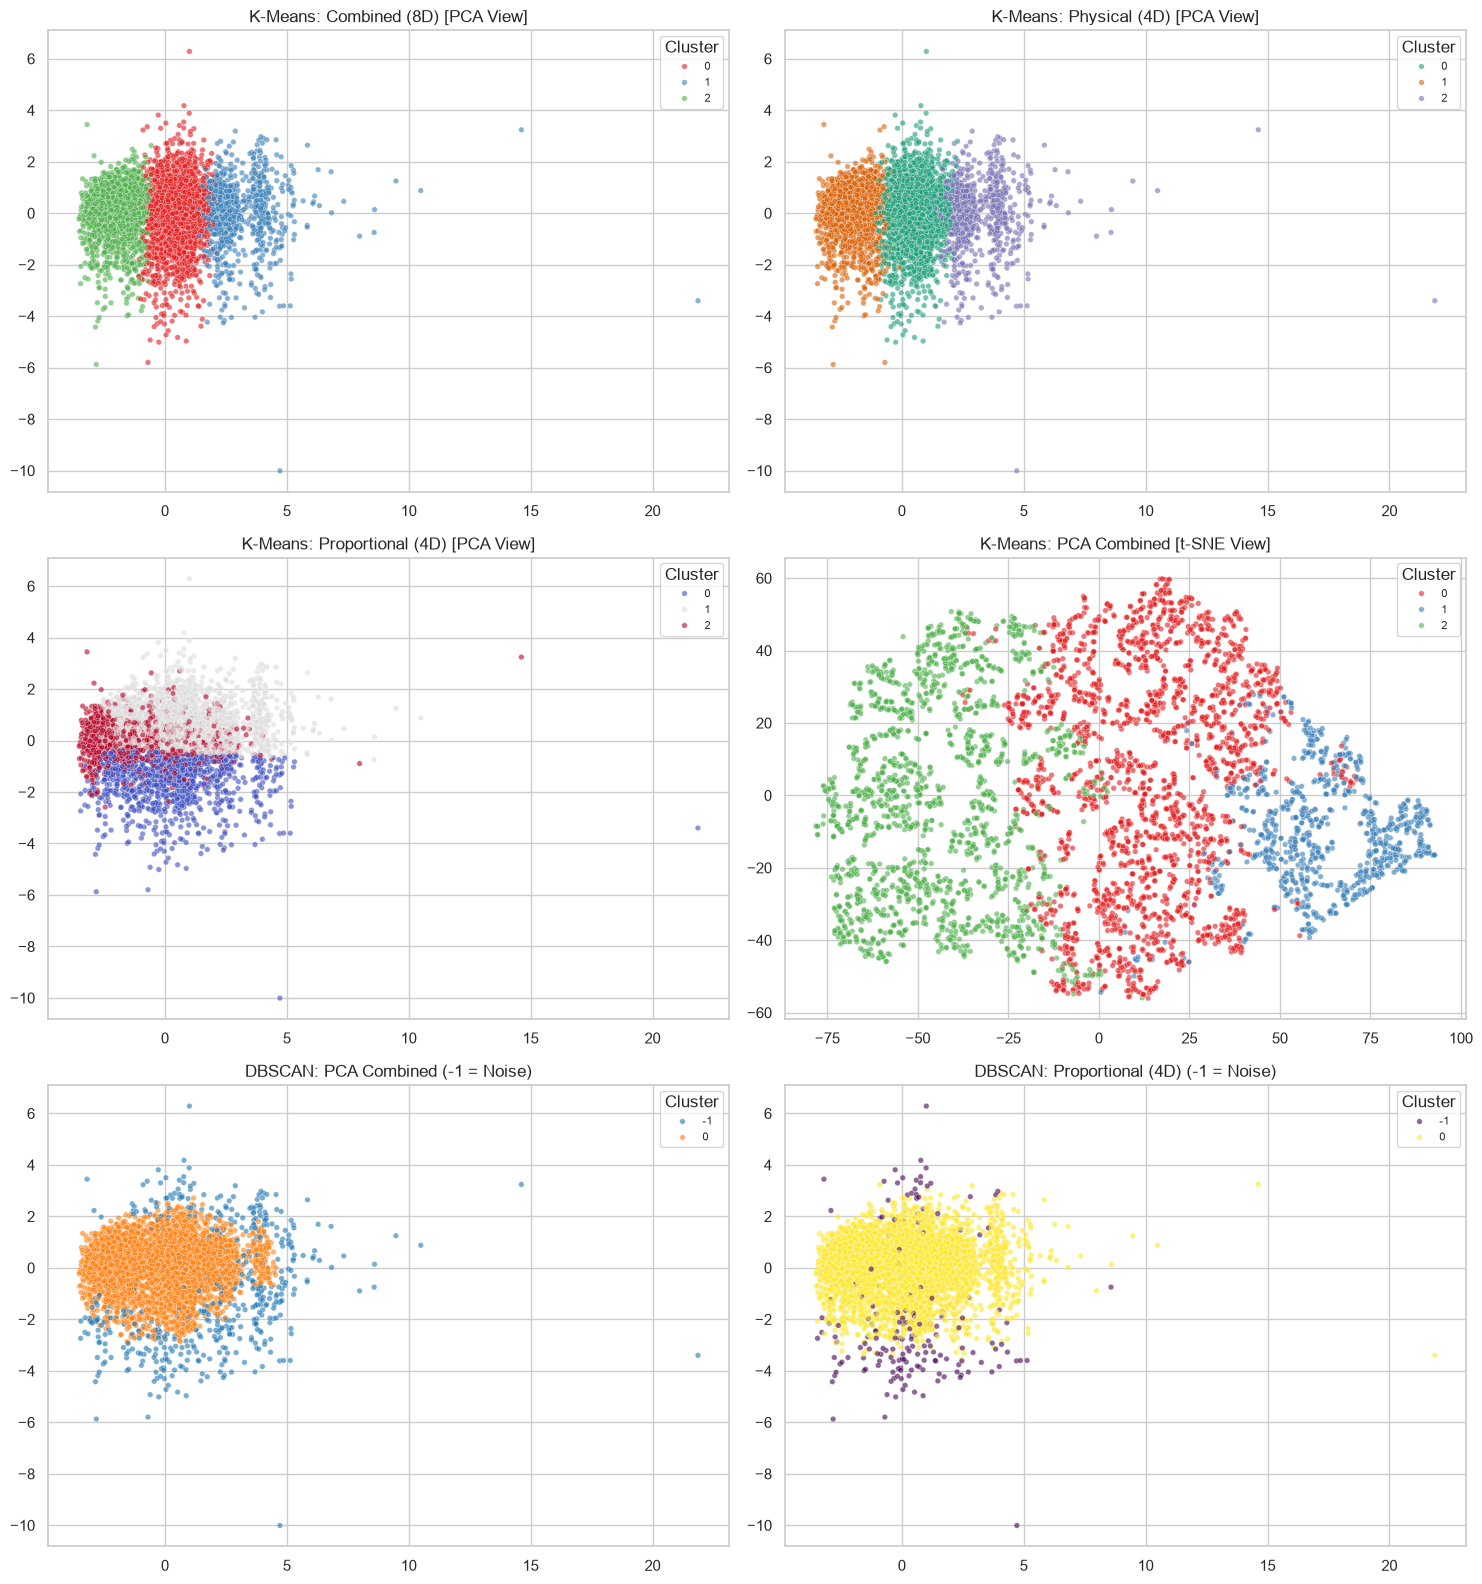

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import NMF
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")

# ==========================================
# 1. Dimensionality Reduction (Aligned Data)
# ==========================================
aligned_physical = combined_scaled[:, :4]
aligned_proportional = combined_scaled[:, 4:]

X_pca_physical = pca_physical.transform(aligned_physical)[:, :2]        
X_pca_proportional = pca_proportional.transform(aligned_proportional)[:, :3]
X_pca_combined = pca_combined.transform(combined_scaled)[:, :3]

combined_non_neg = MinMaxScaler().fit_transform(combined_scaled)
X_nmf_combined = NMF(n_components=3, random_state=42, max_iter=500).fit_transform(combined_non_neg)

X_tsne_combined = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(combined_scaled)

spaces = {
    'Physical (4D)': aligned_physical,
    'Proportional (4D)': aligned_proportional,  # Added Proportional
    'Combined (8D)': combined_scaled,
    'PCA Combined (3D)': X_pca_combined,
    't-SNE Combined (2D)': X_tsne_combined
}

# ==========================================
# 2. K-Means: Optimal Clusters (k=3)
# ==========================================
OPTIMAL_K = 3
cluster_labels = {}
kmeans_summary = []

for name, X_data in spaces.items():
    km = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
    labels = km.fit_predict(X_data)
    cluster_labels[f"KM_{name}"] = labels
    
    kmeans_summary.append({
        'Space': name,
        'Silhouette': round(silhouette_score(X_data, labels), 3),
        'Davies_Bouldin': round(davies_bouldin_score(X_data, labels), 3)
    })

print("=== K-Means Performance (K=3) ===")
print(pd.DataFrame(kmeans_summary).to_string(index=False))

# ==========================================
# 3. DBSCAN Clustering
# ==========================================
dbscan_configs = [
    ('Proportional (4D)', aligned_proportional, 0.80, 10), # Added Proportional
    ('Combined (8D)', combined_scaled, 1.00, 10),
    ('PCA Combined (3D)', X_pca_combined, 0.55, 15)
]

dbscan_summary = []
for name, X_data, eps_val, ms_val in dbscan_configs:
    db = DBSCAN(eps=eps_val, min_samples=ms_val)
    labels = db.fit_predict(X_data)
    cluster_labels[f"DBSCAN_{name}"] = labels
    
    valid_mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    
    sil = silhouette_score(X_data[valid_mask], labels[valid_mask]) if n_clusters >= 2 else np.nan
    dbscan_summary.append({
        'Space': name, 'eps': eps_val, 'Clusters': n_clusters, 
        'Noise_%': round((labels == -1).mean() * 100, 1), 'Silhouette': round(sil, 3)
    })

print("\n=== DBSCAN Performance ===")
print(pd.DataFrame(dbscan_summary).to_string(index=False))

# ==========================================
# 4. Comparative Visualizations (3x2 Grid)
# ==========================================
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

# --- Row 1: Combined & Physical ---
sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1],
                hue=cluster_labels['KM_Combined (8D)'], palette='Set1', alpha=0.6, s=16, ax=axes[0, 0])
axes[0, 0].set_title('K-Means: Combined (8D) [PCA View]')

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1],
                hue=cluster_labels['KM_Physical (4D)'], palette='Dark2', alpha=0.6, s=16, ax=axes[0, 1])
axes[0, 1].set_title('K-Means: Physical (4D) [PCA View]')

# --- Row 2: Proportional (New) & PCA Combined (t-SNE view) ---
sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1],
                hue=cluster_labels['KM_Proportional (4D)'], palette='coolwarm', alpha=0.6, s=16, ax=axes[1, 0])
axes[1, 0].set_title('K-Means: Proportional (4D) [PCA View]')

sns.scatterplot(x=X_tsne_combined[:, 0], y=X_tsne_combined[:, 1],
                hue=cluster_labels['KM_PCA Combined (3D)'], palette='Set1', alpha=0.6, s=16, ax=axes[1, 1])
axes[1, 1].set_title('K-Means: PCA Combined [t-SNE View]')

# --- Row 3: DBSCAN ---
sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1],
                hue=cluster_labels['DBSCAN_PCA Combined (3D)'], palette='tab10', alpha=0.6, s=16, ax=axes[2, 0])
axes[2, 0].set_title('DBSCAN: PCA Combined (-1 = Noise)')

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1],
                hue=cluster_labels['DBSCAN_Proportional (4D)'], palette='viridis', alpha=0.6, s=16, ax=axes[2, 1])
axes[2, 1].set_title('DBSCAN: Proportional (4D) (-1 = Noise)')

for ax in axes.flat:
    ax.legend(title='Cluster', loc='best', fontsize=8)

plt.tight_layout()
plt.show()